In [1]:
import os
from functools import lru_cache

# Core Libraries
import numpy as np
import pandas as pd
import re
import random

# PyTorch Core
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Keras Tokenizer (for vocab + padding)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.utils import resample
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.calibration import CalibratedClassifierCV

# Plotting
import matplotlib.pyplot as plt
from itertools import cycle

# BNLP
import unicodedata
from indicnlp.normalize.indic_normalize import IndicNormalizerFactory
from indicnlp.tokenize.indic_tokenize import trivial_tokenize
from bltk.langtools.banglachars import punctuations
from bnunicodenormalizer import Normalizer as BnNormalizer

# Optional: Progress Bar
from tqdm import tqdm

# Transformers (optional if using BERT later)
from transformers import AutoModel
from transformers import AutoTokenizer


C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Initialize once
bn_unicode_norm = BnNormalizer()
indic_norm = IndicNormalizerFactory().get_normalizer("bn")

# Caching normalization for repeated tokens
@lru_cache(maxsize=1000000)
def cached_bn_norm(token: str) -> str:
    try:
        norm_tok = bn_unicode_norm.normalize(token)
        return norm_tok if norm_tok is not None else token
    except Exception:
        return token

@lru_cache(maxsize=10000)
def cached_stem(word: str) -> str:
    suffixes = [
        'গুলো', 'গুলি', 'টাকে', 'টিতে', 'টায়', 'টা', 'টি',
        'দেরকে', 'দের', 'গুলোকে', 'কে', 'তে', 'তা', 'ের', 'েন',
        'ছি', 'ছিল', 'বেন', 'েছ', 'ে', 'রা', 'য়'
    ]
    for suf in suffixes:
        if word.endswith(suf) and len(word) > len(suf) + 2:
            return word[: -len(suf)]
    return word

def normalize_unicode(text: str) -> str:
    if not isinstance(text, str):
        text = str(text) if text is not None else ""
    return unicodedata.normalize("NFKC", text).strip()

def normalize_bengali(text: str) -> str:
    norm_tokens = [cached_bn_norm(tok) for tok in text.strip().split()]
    norm_tokens = [tok if tok is not None else "" for tok in norm_tokens]
    normalized_sentence = " ".join(norm_tokens)
    return indic_norm.normalize(normalized_sentence)

# --- Punctuation cleaning ---
import string
punctuations = set(string.punctuation) | {"“", "”", "’", "‘", "…"}
escaped_punctuations = re.escape("".join(punctuations))

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = normalize_unicode(text)
    text = normalize_bengali(text)
    text = text.lower()
    text = re.sub(r"(?:@|https?://)\S+", "", text)
    text = re.sub(r"[a-zA-Z0-9]", "", text)
    text = re.sub(r"[{}]+".format(escaped_punctuations), " ", text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# --- STOPWORDS ---
NEGATIONS = {"না", "নয়", "নেই", "কিন্তু", "তবে"}

bengali_stopwords = {
    "অতএব", "অত্যন্ত", "অথচ", "অথবা", "অধিক", "অধিকাংশ", "অনুযায়ী", "অনেক", "অনেকটা", "অনেকটাই",
    "অনেকে", "অনেকেই", "অন্তত", "অন্তর্ভুক্ত", "অন্য", "অন্যথা", "অন্যথায়", "অন্যদিকে", "অন্যান্য", "অপর",
    "অপরদিকে", "অপরাধ", "অপ্রয়োজনীয়", "অবধি", "অবশেষে", "অবশ্য", "অবশ্যই", "অবস্থান", "অর্থাত", "অর্থাৎ",
    "অল্প", "আই", "আগামী", "আগে", "আগেই", "আছে", "আজ", "আজকাল", "আদ্যন্ত", "আদ্যভাগে",
    "আধুনিক", "আপনার", "আপনি", "আবার", "আমরা", "আমাকে", "আমাদের", "আমার", "আমি", "আমিও",
    "আর", "আরও", "আশেপাশে", "আসলে", "আসা", "ই", "ইত্যাদি", "ইহা", "উচিত", "উত্তর",
    "উনি", "উপর", "উপরন্তু", "উপরে", "উল্লেখযোগ্য", "উল্লেখ্য", "এ", "এঁদের", "এঁরা", "এই",
    "এক", "একই", "একটি", "একটু", "একবার", "একাংশ", "একে", "এক্", "এখন", "এখনও",
    "এখানে", "এখানেই", "এছাড়া", "এছাড়াও", "এটা", "এটাই", "এটাও", "এটি", "এত", "এতটাই",
    "এতে", "এদিকে", "এদের", "এব", "এবং", "এবার", "এমন", "এমনকি", "এমনকী", "এমনি",
    "এর", "এরা", "এল", "এস", "এসব", "এসে", "এসেছিল", "ঐ", "ও", "ওঁদের",
    "ওঁর", "ওঁরা", "ওই", "ওকে", "ওখানে", "ওদের", "ওর", "ওরা", "কখন", "কখনও",
    "কখনো", "কত", "কবে", "কমনে", "কয়েক", "কয়েকটি", "করছে", "করছেন", "করতে", "করবে",
    "করবেন", "করলে", "করলেন", "করা", "করাই", "করায়", "করার", "করি", "করিতে", "করিয়া",
    "করিয়ে", "করে", "করেই", "করেছিলেন", "করেছে", "করেছেন", "করেন", "কাউকে", "কাছ", "কাছে",
    "কাজ", "কাজে", "কাজেই", "কারও", "কারণ", "কারণে", "কি", "কিংবা", "কিছু", "কিছুই",
    "কিন্তু", "কী", "কে", "কেউ", "কেউই", "কেখা", "কেন", "কেননা", "কেবল", "কোটি",
    "কোথাও", "কোথায়", "কোন", "কোনও", "কোনো", "ক্ষেত্রে", "কয়েক", "খুব", "গিয়ে", "গিয়েছিল",
    "গিয়েছে", "গিয়ে", "গুলি", "গেছে", "গেল", "গেলে", "গোটা", "চলছে", "চলে", "চান",
    "চায়", "চার", "চালু", "চেয়ে", "চেষ্টা", "ছাড়া", "ছাড়াও", "ছিল", "ছিলেন", "জন",
    "জনকে", "জনের", "জন্য", "জন্যওজে", "জানতে", "জানা", "জানানো", "জানায়", "জানিয়ে", "জানিয়েছে",
    "জে", "জ্নজন", "টাই", "টাকায়", "টি", "ঠিক", "ঠিকই", "তখন", "তখনই", "তখনও",
    "তত", "ততক্ষণ", "তথা", "তদুপরি", "তবু", "তবুও", "তবে", "তা", "তাঁকে", "তাঁদের",
    "তাঁর", "তাঁরা", "তাঁাহারা", "তাই", "তাও", "তাকে", "তাছাড়া", "তাতে", "তাদের", "তার",
    "তারপর", "তারা", "তারৈ", "তাহলে", "তাহা", "তাহাতে", "তাহার", "তিনঐ", "তিনি", "তিনিও",
    "তুমি", "তুলনা", "তুলনায়", "তুলে", "তেমন", "তো", "তোমার", "থাকবে", "থাকবেন", "থাকা",
    "থাকায়", "থাকে", "থাকেন", "থেকে", "থেকেই", "থেকেও", "দিকে", "দিতে", "দিন", "দিয়ে",
    "দিয়েছে", "দিয়েছেন", "দিলেন", "দু", "দুই", "দুটি", "দুটো", "দেওয়া", "দেওয়ার", "দেওয়া",
    "দেখতে", "দেখা", "দেখে", "দেন", "দেয়", "দ্বারা", "ধরা", "ধরে", "ধামার", "নতুন",
    "নয়", "না", "নাই", "নাকি", "নাগাদ", "নানা", "নিজে", "নিজেই", "নিজেদের", "নিজের",
    "নিতে", "নিম্নলিখিত", "নিয়ে", "নিয়ে", "নেই", "নেওয়া", "নেওয়ার", "নেওয়া", "নয়", "পক্ষে",
    "পর", "পরও", "পরবর্তী", "পরবর্তীতে", "পরিষ্কার", "পরিসংখ্যানগত", "পরে", "পরেই", "পরেও", "পর্যন্ত",
    "পাওয়া", "পাচ", "পারা", "পারি", "পারে", "পারেন", "পাশাপাশি", "পি", "পূর্বে", "পেয়ে",
    "পেয়্র্", "প্রতি", "প্রথম", "প্রথমে", "প্রধানত", "প্রভৃতি", "প্রযন্ত", "প্রাথমিক", "প্রায়", "প্রায়ই",
    "প্রায়", "প্রয়ন্ত", "ফলে", "ফিরে", "ফের", "বক্তব্য", "বটে", "বদলে", "বন", "বরং",
    "বর্তমানে", "বলতে", "বলল", "বললেন", "বলা", "বলে", "বলেছেন", "বলেন", "বসে", "বহু",
    "বা", "বাদে", "বার", "বি", "বিনা", "বিভিন্ন", "বিশেষ", "বিশেষ করে", "বিশেষত", "বিষয়টি",
    "বিষয়ে", "বেশ", "বেশকিছু", "বেশি", "বেশিরভাগ", "ব্যবহার", "ব্যাপারে", "ভাবে", "ভাবেই", "মতো",
    "মতোই", "মধ্যভাগে", "মধ্যে", "মধ্যেই", "মধ্যেও", "মনে", "মাঝে", "মাত্র", "মাধ্যমে", "মূলত",
    "মোট", "মোটামুটি", "মোটেই", "যখন", "যখনই", "যত", "যতক্ষণ", "যতটা", "যথা", "যথেষ্ট",
    "যদি", "যদিও", "যা", "যাঁর", "যাঁরা", "যাইহোক", "যাওয়া", "যাওয়ার", "যাওয়া", "যাকে",
    "যাচ্ছে", "যাতে", "যাদের", "যান", "যাবে", "যায়", "যার", "যারা", "যিনি", "যে",
    "যেকোনো", "যেখানে", "যেতে", "যেন", "যেমন", "র", "রকম", "রয়েছে", "রাখা", "রেখে",
    "লক্ষ", "লক্ষ্য", "শুধু", "শুরু", "সংক্ষেপে", "সংশ্লিষ্ট", "সঙ্গে", "সঙ্গেও", "সদৃশ", "সব",
    "সবার", "সমস্ত", "সম্পর্কিত", "সম্প্রতি", "সম্ভবত", "সহ", "সহিত", "সাথে", "সাধারণ", "সাধারণত",
    "সামগ্রিক", "সামগ্রিকভাবে", "সামনে", "সি", "সুতরাং", "সে", "সেই", "সেখান", "সেখানে", "সেটা",
    "সেটাই", "সেটাও", "সেটি", "স্পষ্ট", "স্বয়ং", "স্বাভাবিক", "হইতে", "হইবে", "হইয়া", "হওয়া",
    "হওয়ায়", "হওয়ার", "হচ্ছে", "হত", "হতে", "হতেই", "হন", "হবে", "হবেন", "হয়",
    "হয়তো", "হয়নি", "হয়ে", "হয়েই", "হয়েছিল", "হয়েছিলো", "হয়েছে", "হয়েছেন", "হল", "হলে",
    "হলেই", "হলেও", "হলো", "হাজার", "হিসাবে", "হৈলে", "হোক", "হয়"
}
filtered_stopwords = bengali_stopwords - NEGATIONS

# Tokenizer (uses Indic NLP)
def tokenize(text: str) -> list[str]:
    return trivial_tokenize(text, lang="bn")

# Full preprocessing
def preprocess(text: str) -> str:
    txt = clean_text(text)
    tokens = tokenize(txt)
    tokens = [cached_stem(w) for w in tokens if w not in filtered_stopwords and len(w) > 1]
    return " ".join(tokens)


In [3]:
# # Define positive Bengali words
# positive_words = {
#     "অংশগ্রহণমূলক", "অগ্রসর", "অতিথিপরায়ণ", "অতুলনীয়", "অত্যন্ত ভালো", "অধ্যবসায়ী", "অনন্য", "অনবদ্য", "অনিন্দ্য", "অনুপ্রেরণাদায়ী",
#     "অনুরণিত", "অপূর্ব", "অবিরাম", "অবিশ্বাস্য", "অভিজ্ঞ", "অভিনন্দন", "অমায়িক", "অর্জন", "অর্জনমূলক", "অর্থবহ অর্জন",
#     "অসাধারণ", "অ্যাওয়ার্ডপ্রাপ্ত", "আওয়াজময়", "আকর্ষণীয়", "আঙ্গিক শিল্প", "আত্মঅনুপ্রেরণা", "আত্মবিশ্বাসী", "আত্মমুগ্ধ", "আদর্শবান", "আদান-প্রদান",
#     "আধিপত্য", "আধুনিক", "আনন্দ প্রদায়ক", "আনন্দদায়ক", "আনন্দময়", "আন্তঃসামাজিক", "আন্তরিক", "আন্তরিক সমর্থন", "আন্তর্জাতিক খ্যাতিপ্রাপ্ত", "আবেগপ্রবণ",
#     "আবেদ্য", "আরোগ্য", "আলোকচিত্রণ", "আলোকিত", "আলোকিত ধারণা", "আশা জাগানো", "আশার আলো", "আশ্চর্যজনক", "উচ্ছ্বাস", "উজ্জীবিত",
#     "উজ্জ্বল", "উত্তম", "উত্সাহজনক", "উদার", "উদার বিশ্বাস", "উদারপন্থী", "উদ্দীপনাময়", "উদ্দীপনার ফল", "উদ্দীপ্ত", "উদ্দেশ্যপূরণ",
#     "উদ্বুদ্ধ", "উদ্ভাবনী", "উদ্যমী", "উদ্যোক্তা মনের", "উন্নত", "উন্নতির পথ", "উন্নয়নমুখী", "উপাধিসম্পন্ন", "উল্লসিত", "উৎকর্ষ",
#     "উৎসাহজনক বক্তব্য", "উৎসাহী", "একতাবদ্ধ", "একাগ্রতা", "একান্ত ভালো", "একেবারে অসাধারণ", "এগিয়ে চিন্তা", "এমনিষ্ট", "ঐতিহ্যবাহী", "ওয়েভীয়",
#     "কবিতাময়", "কর্পোরেট", "কর্মঠ", "কর্মসতর্ক", "কল্পনাপ্রবণ", "কল্যাণকামী", "কাব্যবোধ", "কার্যকর", "কৃতজ্ঞতা", "ক্ষমতাশালী",
#     "খাঁটি", "খুশি", "গর্বিত", "গীতবোধ", "গুণগত", "গৌরবজনক", "চতুর", "চমৎকার", "চিত্তাকর্ষক", "চিত্রকর",
#     "চিত্রাঙ্কন", "চেয়ারপ্রাপ্ত", "জয় হোক", "জয়ী", "টুকরো টুকরো চিন্তা", "দক্ষতা", "দয়ালু", "দর্শনীয়", "দায়িত্বশীল", "দারুণ",
#     "দারুণ কাজ", "দার্শনিক চিন্তা", "দায়িত্ববান", "দীপ্ত", "দূরদর্শী", "দৃঢ়", "দৃঢ়প্রতিজ্ঞ", "দৃষ্টিনন্দন", "দৃষ্টিসম্পন্ন", "ধারাবাহিক উন্নতি",
#     "নকশাময়", "নম্র", "নম্রমনা", "নাট্যগুণ", "নান্দনিক", "নিখুঁত", "নিবেদিত", "নির্দ্বিধায়", "নির্ভরযোগ্য", "নির্ভীক",
#     "নিশ্চিত", "নিষ্কলুষ", "নিষ্ঠাবান", "নীতিবান", "নৃত্যগতি", "নৈর্ব্যক্তিক", "ন্যায়পরায়ণ", "পরিকল্পনাময়", "পরিচালন দক্ষ", "পরিপূর্ণ",
#     "পরিবারমুখী", "পরিশ্রমী", "পরোপকারী", "পারদর্শী", "পারস্পরিক", "প্রকাশক্ষম", "প্রজ্ঞাপূর্ণ", "প্রজ্ঞাবান", "প্রতিযোগিতামূলক", "প্রভাতরূপ",
#     "প্রভাবশালী", "প্রযুক্তিগত অগ্রগতি", "প্রশংসনীয়", "প্রশংসানীয়", "প্রশস্ত", "প্রশান্ত", "প্রশান্তি", "প্রাণবন্ত", "প্রিয়জনবান্ধব", "প্রেরণাদায়ক",
#     "প্রেরণাময়", "ফলপ্রসূ", "বন্ধনমূলক", "বন্ধুত্বমূলক", "বন্ধুত্বসূচক", "বরণীয়", "বর্ণাঢ্য", "বস্তুনিষ্ঠ", "বাঁচার আনন্দ", "বাকশিল্প",
#     "বিখ্যাত", "বিনয়ী", "বিশুদ্ধ মনোভাব", "বিশ্বস্ত", "বিশ্বের মান", "বিশ্লেষণী", "বুদ্ধিমান", "বেড়ে চলা", "বৈচিত্র্যবদ্ধ", "বৈজ্ঞানিক অর্জন",
#     "ব্যঞ্জনাময়", "ব্যতিক্রমী", "ব্যাপক মনোভাব", "ভদ্র", "ভরসাযোগ্য", "ভলোমুলক", "ভাবনাময়", "ভালোবাসা", "ভাষাগত দখল", "মজাদার",
#     "মঞ্চবোধ", "মধুর", "মধুর সম্পর্ক", "মননশীল", "মনোভোগ", "মনোমুগ্ধকর", "মনোযোগী", "মহান", "মহৎ", "মাধুর্যময়",
#     "মানব বন্ধন", "মানবিক", "মানসম্পন্ন", "মার্জিত", "মিষ্টি", "মুক্তমনা", "মুগ্ধ", "মুদ্রণশিল্প", "মূল্যবান সাফল্য", "মেধাবী",
#     "মৈত্রী", "যথার্থ", "যোগাযোগযোগ্য", "রঙ্গভঙ্গিমাপূর্ণ", "রহস্যময়", "রীতিনির্মাতা", "রূপময়", "রূপসজ্জা", "রূপান্তরকামী", "রেকর্ড-নির্মাতা",
#     "লক্ষ্যমুখী", "লাবণ্য", "লোভনীয়", "শক্তিমান", "শক্তিশালী", "শব্দকল্পনা", "শব্দরহস্য", "শান্তিপূর্ণ", "শান্তিপূর্ণ সমঝোতা", "শিল্পগ্রন্থ",
#     "শৃঙ্খলার", "শ্রদ্ধা", "শ্রদ্ধাবান্দব", "শ্রদ্ধাভাজন", "শ্রদ্ধাশীল", "শ্রদ্ধেয়", "শ্রেষ্ঠ", "শ্রেষ্ঠত্ব", "সংগীতাত্মক", "সক্রিয়",
#     "সখ্য", "সতেজতা", "সত্য", "সদাচার", "সদ্ব্যবহার", "সদ্যাগত", "সন্মানজনক", "সন্মিলিত", "সমন্বিত শিল্প", "সমবেদনা",
#     "সমালোচনামূলক চিন্তা", "সমৃদ্ধ", "সম্প্রকাশিত", "সম্প্রসারিত", "সম্ভাবনাময়", "সম্মাননীয়", "সম্মানিত", "সর্বজনীন", "সহকর্মীপ্রিয়", "সহজ",
#     "সহনশীল", "সহনশীল আলোচনায়", "সহমতান্বিত", "সহমর্মী", "সহানুভূতিপূর্ণ", "সহানুভূতির প্রকাশ", "সহানুভূতিশীল", "সহায়ক", "সহিত", "সাফল্যময়",
#     "সাবলীল", "সামাজিক", "সার্টিফাইড", "সাহসী", "সাহসী পদক্ষেপ", "সাহসের উদাহরণ", "সাহিত্যবোধ", "সুনির্দিষ্ট", "সুন্দর", "সুর-সুরে",
#     "সুরুচিপূর্ণ", "সুশাসিত", "সৃজনপট", "সৃজনশীল", "সৃজনশীলতা", "সৃষ্টিশীল", "সেরা", "সেরা পজিশন", "সৌজন্যবতী", "সৌজন্যমূলক",
#     "সৌন্দর্য", "সৌন্দর্যনিরূপণ", "সৌম্য", "সৌম্যবাচন", "স্থিতিশীল", "স্নিগ্ধ", "স্পন্দনশীল", "স্পষ্টবাদী", "স্ব-উন্নতি", "স্বপ্নপালক",
#     "স্বপ্নিল", "স্বয়ংসম্পূর্ণতা", "স্বর্ণালী", "স্বাস্থ্যকর", "স্বীকৃত", "স্মরণীয়", "সৎ", "হংস", "হালকা", "হিরণ্ময়",
#     "হীরক", "হৃদয়স্পর্শী", "তুমি অবিস্মরণীয়।", "তুমি অসাধারণ।", "তুমি আশ্চর্যকর!", "তুমি উদার ও সহানুভূতিশীল।", "তুমি একজন প্রকৃত নেতা।", "তুমি একাগ্র।", "তুমি চমৎকার বন্ধু।", "তুমি দায়িত্বশীল।",
#     "তুমি দারুণভাবে উন্নত করেছো।", "তুমি দৃষ্টান্ত!", "তুমি পরিপূর্ণ।", "তুমি বিতর্কশীল নয়।", "তুমি বিশ্বস্ত।", "তুমি ব্যবহারিক ও চতুর।", "তুমি ভাল উদাহরণ।", "তুমি মানবদরদী।", "তুমি মেধাবী।", "তুমি শান্তিপূর্ণ।",
#     "তুমি সংহত ও মেধাবী।", "তুমি সকলের প্রিয়।", "তুমি সত্যিই মূল্যবান।", "তুমি সর্বদা উন্নতিসাধনকারী।", "তুমি সাহসী।", "তুমি সুন্দরভাবে সংহত।", "তুমি স্থিরমনা।", "তোমার অনুগ্রহ অপরিসীম।", "তোমার অভিব্যক্তি প্রাসঙ্গিক।", "তোমার আচরণ নম্র।",
#     "তোমার আচরণ প্রশংসনীয়।", "তোমার উদ্যোগ ফলপ্রসূ।", "তোমার উপদেশ মূল্যবান।", "তোমার উপস্থিতি শ্রেষ্ঠ।", "তোমার উপস্থিতিও মূল্যবান।", "তোমার কথা স্পষ্ট।", "তোমার চিন্তা অনুপ্রেরণীয়।", "তোমার দৃষ্টি ভিন্ন।", "তোমার নেতৃত্ব প্রশংসিত।", "তোমার পরামর্শ গ্রহণযোগ্য।",
#     "তোমার পরিশ্রম ফলপ্রসূ।", "তোমার প্রচেষ্টা প্রশংসনীয়।", "তোমার প্রেরণা অসাধারণ।", "তোমার মতো কেউ আর নেই।", "তোমার মনোযোগ অদ্ভুত।", "তোমার শক্তি অনন্য।", "তোমার সাহস প্রশংসনীয়।", "তোমার সৃজনশীলতা আনন্দদায়ক।", "তোমার সৃষ্টি চমৎকার।", "তোমার স্পর্ধা বৃথা নয়।",
#     "তোমার হাসি অনুপ্রেরণা।", "ভালো কাজ করেছো!"
# }
# negative_words = {
#     "অধম", "অপকর্মী", "অপদার্থ", "অপমান", "অশ্লীল", "অসভ্য", "অস্পৃশ্য", "আবাল চোদা", "উপ্তা কইরা চুদমু", "উপ্তা কইরা চুদা দিমু",
#     "উষ্টা খা", "এক কানে হোল ভইরা আরেক করমু", "কম্বক্ত", "কাঠ্ঠির বেট্যা", "কান্দে ফালাইয়া তর মায়েরে চুদি", "কাফের", "কুত্তা", "কুত্তাচোদা", "কুত্তার পুকটি চাটামু", "কুত্তার বাচ্চা",
#     "কুত্তার বাচ্ছা", "কুত্তার হোল", "কুলটা", "খবিশ", "খবিশ চোদা", "খাঙ্কিরপোলা", "খানকি", "খান্কি মাগি", "খান্কি মাগির পোলা",
#     "খুন", "খুন করব", "খ্রিস্টান কুকুর", "গলা কাটব", "গাধা", "গালি", "গাড় মারা খা", "গুদা", "গুদির ব্যাটা", "গুদের বাল",
#     "গুয়ার ভিতরে ভইড়া দিমু", "গেলমান", "গোলাম আযম", "গো আর জুতা", "গোয়ালার বাচ্চা", "গোলাম আযম", "গোস্তের লাঠি সাটামু", "ঘর থেকে তাড়াব", "ঘৃণা", "চতুরচোর",
#     "চামার", "চামড়া ছুইল্লা লবণ লাগামু", "চুতমারানি", "চুতমারানীর পোলা", "চুদনা মাগী", "চুদমু", "চুদানির পো", "চুদির পোলা", "চুদির ভাই", "চোখ তুলব",
#     "চোদ", "চোদনা", "চোদা", "চোর", "ছি ছি ছি", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "জঘন্য", "জল্লাদ", "জাত খারাপ", "জাতিচ্যুত",
#     "জীবন নষ্ট করব", "জ্যান্ত পুড়িয়ে মারব", "টিটকারি", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "তর ধন দিয়া মাটি খুড়ুম", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু",
#     "তর বাপের বিচি বেইচা কটকটি খামু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়রে চুদি", "তর মায়রে বাপ", "তর মায়ের ঐখানে বিছাতু পাতা", "তর মায়ের ভুদাতে পোকা", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু",
#     "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদায় আউটপুট", "তর মায়েরে চিচিং ফাক", "তর হোগায় ইনপুট", "তরে গোআ দিয়া চুদামু", "তিনকোনা", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু",
#     "তোর নাকে হাইগ্যা দিমু", "তোর বউয়ের মুসলমানি দিমু", "তোর বাপ গাইড়্যা", "তোর বাপে তোর নানা", "তোর বাপের ব্যাটা", "তোর হউরিরে ডিগবাজী", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "দলিত কুকুর", "ধরাশায়ী করব", "ধর্ম ছাড়",
#     "ধর্ম যুদ্ধ", "ধর্মদ্রোহী", "ধর্মান্তর", "ধর্মের অপমান", "ধর্মের নামে হিংসা", "ধর্মের শত্রু", "ধর্ষক", "ধর্ষণ", "ধোন", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু",
#     "ধোনের বাল", "নটি", "নটি মাগি", "নটি মাগির ঝি", "নটি মাগির পোলা", "নরকগামী", "নরাধম", "নষ্ট", "নাটকির পো", "নাস্তিক",
#     "নিচ", "নিজামী চোদা", "নিজামীর গোয়ার কৃমি", "নিবীর্জ", "নীচ জাত", "নীজামী", "পাজি", "পাথর মারব", "পাপী", "পাষণ্ড",
#     "পিটিয়ে মারব", "পুকটি", "পুকটি মারা খা", "পুক্টি", "পুটকি", "পুটকিতে বাশ দিমু", "পূজা বন্ধ", "পেল", "ফাটা কন্ডমের ফসল", "বটই",
#     "বদমাশ", "বদমায়েশ", "বস্তা", "বাইনচোদ", "বানচোত", "বাপের আগে বাল ফালায়", "বারবাতারি", "বাল", "বাল ছাল", "বাল ফালাইয়া আটি বান",
#     "বাল ফালায়া আটিঁ বান্ধা", "বাল ফালায়া খালে নামানো", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", "বালে বালে গিট্টু", "বালের রয়েল বেঙ্গল উকুন", "বুদ্ধি নষ্ট", "বেশ্যা", "বেশ্যা মাগী", "বেশ্যার পুত্র", "বোকা আচোদা",
#     "বোকাচোদা", "বোমা মারব", "বৌদ্ধ নষ্ট", "ভইরা দিমু", "ভাতার চুদা", "ভুদার বেটা", "ভুস্কি মাগির পোলা", "ভেড়াচ্চোদা", "ভৈরব মাগী", "ভোগ",
#     "ভোদাই", "ভোদার বাল", "মইত্যা নিজামী", "মজবাশার", "মন্দির ভাঙো", "মর বাচ্চা", "মসজিদ ধ্বংস", "মহাবুবস্", "মাই চুষ", "মাইগ্যা",
#     "মাউড়া চোদা", "মাগি", "মাগিবাজ", "মাঙ্গির পুত", "মাঙ্গের নাতি", "মাঙ্গের পোলা", "মাথা ফাটব", "মাদার চোদ", "মারধর", "মাসিকের ত্যানা",
#     "মীরজাফর", "মুখে থু", "মুসলিম কুকুর", "মূর্খ", "মেয়েলি গালি", "মেরে ফেলব", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "যৌন",
#     "রক্ত ঝরাব", "রাঁড়", "লটির পো", "লটির বেটা", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "লাথ্থি দিমু", "লান্ড চুষ", "লেওরা", "ল্যাউড়ার পুত", "ল্যাদানী",
#     "শত্রু", "শয়তান", "শাউয়া", "শালা", "শালার পো শালা", "শুয়োরের বাচ্চা", "সুদখোর", "স্ত্রীজাত", "হত্যা", "হত্যাকারী",
#     "হরিজন", "হাঁড়িচ্যাটা", "হাইগ্যা", "হাউয়ার নাতি", "হাউয়ার পো", "হাড় ভাঙব", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "হারামখোর", "হারামজাদা", "হারামি",
#     "হারামির বাচ্চা", "হালা ল্যাওড়া চোদা", "হিটলার", "হিন্দু কুকুর", "হুমুন্দির পুত", "হোগা চাটা", "হোগার ভিতরে ভইড়া দিমু", "হোল", "হোল টাইনা পুকটিতে ভর", "হোলচাটা",
#     "হোলের চুলকানী"
# }

# # Function to check for positive words
# def is_positive(comment):
#     return any(word in comment for word in positive_words)

# # Function to check for negative words
# def is_negative(comment):
#     return any(word in comment for word in negative_words)

# # Custom Methods
# def classify_sentiment(row):
#     if row['category'] == 1:
#         return 'negative'
#     elif is_negative(row['comment']):
#         return 'negative'
#     elif is_positive(row['comment']):
#         return 'positive'
#     else:
#         return 'neutral'

# # Load existing datasets
# # --- Dataset 1: bangla_online_comments_dataset.csv ---
# df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bangla_online_comments_dataset.csv')
# df1 = df1.rename(columns={'comment': 'comment', 'label': 'category'})[['comment', 'category']]
# df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()

# df1['is_positive'] = df1['comment'].apply(is_positive)
# df1['is_negative'] = df1['comment'].apply(is_negative)

# conditions = [
#     (df1['category'] == 'not bully') & df1['is_positive'],
#     (df1['category'] == 'not bully') & ~df1['is_positive'],
#     (df1['category'].isin(['troll', 'religious'])) & ~df1['is_negative']
# ]
# choices = [
#     'positive',  # Condition 1
#     'neutral',   # Condition 2
#     'neutral'    # Condition 3
# ]
# df1['sentiment'] = np.select(conditions, choices, default='negative')  # Fallback to negative
# df1 = df1[df1['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# # --- Dataset 2: Bengali hate speech.csv ---
# df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/Bengali hate speech.csv')
# df2 = df2[['sentence', 'hate']]
# df2 = df2.rename(columns={'sentence': 'comment', 'hate': 'category'})[['comment', 'category']]
# df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()

# # Apply classification
# df2['sentiment'] = df2.apply(classify_sentiment, axis=1)
# df2 = df2[df2['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# # --- Dataset 3: bdsh_train.csv ---
# df3 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bdsh_train.csv')
# df3 = df3.rename(columns={
#     'sentence': 'comment',
#     'hate speech': 'category'
# })[['comment', 'category']]
# df3['comment'] = df3['comment'].astype(str).fillna('').str.strip()

# # Apply classification
# df3['sentiment'] = df3.apply(classify_sentiment, axis=1)
# df3 = df3[df3['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# # Load SentNoB dataset
# df4 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
# df4 = df4.rename(columns={
#     'Data': 'comment',
#     'Label': 'category'
# })[['comment', 'category']]

# df4['comment'] = df4['comment'].astype(str).fillna('').str.strip()

# # Map numerical labels to sentiments
# label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
# df4['sentiment'] = df4['category'].map(label_mapping)
# df4 = df4[df4['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# # Load the Saqib dataset
# df5 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
# df5 = df5.rename(columns={
#     'text': 'comment',
#     'sentiment': 'sentiment'
# })[['comment', 'sentiment']]

# df5['comment'] = df5['comment'].astype(str).fillna('').str.strip()
# df5 = df5[df5['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# # --- Dataset 6: collected.csv ---
# df6 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/collected.csv')
# df6 = df6.rename(columns={
#     'sentence': 'comment',
#     'hate speech': 'category'
# })[['comment', 'category']]
# df6['comment'] = df6['comment'].astype(str).fillna('').str.strip()

# # Apply classification
# df6['sentiment'] = df6.apply(classify_sentiment, axis=1)
# df6 = df6[df6['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# # Ensure final cleaned versions with consistent columns
# df1_final = df1[['comment', 'sentiment']]
# df2_final = df2[['comment', 'sentiment']]
# df3_final = df3[['comment', 'sentiment']]
# df4_final = df4[['comment', 'sentiment']]
# df5_final = df5[['comment', 'sentiment']]
# df6_final = df6[['comment', 'sentiment']]

# # Merge all datasets
# merged_df = pd.concat([
#     df1_final,
#     df2_final,
#     df3_final,
#     df4_final,
#     df5_final,
#     df6_final
# ], ignore_index=True)

# # Drop rows with missing values in key columns (just in case)
# merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)

# merged_df = merged_df.rename(columns={
#     'comment': 'comment',
#     'sentiment': 'category'
# })[['comment', 'category']]

# # Save merged dataset
# merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PN.csv", index=False)
# print("✅ Final dataset merged and saved as 'raw_comments_PN.csv'")

In [4]:
# Define positive Bengali words
positive_words = {
    "অংশগ্রহণমূলক", "অগ্রসর", "অতিথিপরায়ণ", "অতুলনীয়", "অত্যন্ত ভালো", "অধ্যবসায়ী", "অনন্য", "অনবদ্য", "অনিন্দ্য", "অনুপ্রেরণাদায়ী",
    "অনুরণিত", "অপূর্ব", "অবিরাম", "অবিশ্বাস্য", "অভিজ্ঞ", "অভিনন্দন", "অমায়িক", "অর্জন", "অর্জনমূলক", "অর্থবহ অর্জন",
    "অসাধারণ", "অ্যাওয়ার্ডপ্রাপ্ত", "আওয়াজময়", "আকর্ষণীয়", "আঙ্গিক শিল্প", "আত্মঅনুপ্রেরণা", "আত্মবিশ্বাসী", "আত্মমুগ্ধ", "আদর্শবান", "আদান-প্রদান",
    "আধিপত্য", "আধুনিক", "আনন্দ প্রদায়ক", "আনন্দদায়ক", "আনন্দময়", "আন্তঃসামাজিক", "আন্তরিক", "আন্তরিক সমর্থন", "আন্তর্জাতিক খ্যাতিপ্রাপ্ত", "আবেগপ্রবণ",
    "আবেদ্য", "আরোগ্য", "আলোকচিত্রণ", "আলোকিত", "আলোকিত ধারণা", "আশা জাগানো", "আশার আলো", "আশ্চর্যজনক", "উচ্ছ্বাস", "উজ্জীবিত",
    "উজ্জ্বল", "উত্তম", "উত্সাহজনক", "উদার", "উদার বিশ্বাস", "উদারপন্থী", "উদ্দীপনাময়", "উদ্দীপনার ফল", "উদ্দীপ্ত", "উদ্দেশ্যপূরণ",
    "উদ্বুদ্ধ", "উদ্ভাবনী", "উদ্যমী", "উদ্যোক্তা মনের", "উন্নত", "উন্নতির পথ", "উন্নয়নমুখী", "উপাধিসম্পন্ন", "উল্লসিত", "উৎকর্ষ",
    "উৎসাহজনক বক্তব্য", "উৎসাহী", "একতাবদ্ধ", "একাগ্রতা", "একান্ত ভালো", "একেবারে অসাধারণ", "এগিয়ে চিন্তা", "এমনিষ্ট", "ঐতিহ্যবাহী", "ওয়েভীয়",
    "কবিতাময়", "কর্পোরেট", "কর্মঠ", "কর্মসতর্ক", "কল্পনাপ্রবণ", "কল্যাণকামী", "কাব্যবোধ", "কার্যকর", "কৃতজ্ঞতা", "ক্ষমতাশালী",
    "খাঁটি", "খুশি", "গর্বিত", "গীতবোধ", "গুণগত", "গৌরবজনক", "চতুর", "চমৎকার", "চিত্তাকর্ষক", "চিত্রকর",
    "চিত্রাঙ্কন", "চেয়ারপ্রাপ্ত", "জয় হোক", "জয়ী", "টুকরো টুকরো চিন্তা", "দক্ষতা", "দয়ালু", "দর্শনীয়", "দায়িত্বশীল", "দারুণ",
    "দারুণ কাজ", "দার্শনিক চিন্তা", "দায়িত্ববান", "দীপ্ত", "দূরদর্শী", "দৃঢ়", "দৃঢ়প্রতিজ্ঞ", "দৃষ্টিনন্দন", "দৃষ্টিসম্পন্ন", "ধারাবাহিক উন্নতি",
    "নকশাময়", "নম্র", "নম্রমনা", "নাট্যগুণ", "নান্দনিক", "নিখুঁত", "নিবেদিত", "নির্দ্বিধায়", "নির্ভরযোগ্য", "নির্ভীক",
    "নিশ্চিত", "নিষ্কলুষ", "নিষ্ঠাবান", "নীতিবান", "নৃত্যগতি", "নৈর্ব্যক্তিক", "ন্যায়পরায়ণ", "পরিকল্পনাময়", "পরিচালন দক্ষ", "পরিপূর্ণ",
    "পরিবারমুখী", "পরিশ্রমী", "পরোপকারী", "পারদর্শী", "পারস্পরিক", "প্রকাশক্ষম", "প্রজ্ঞাপূর্ণ", "প্রজ্ঞাবান", "প্রতিযোগিতামূলক", "প্রভাতরূপ",
    "প্রভাবশালী", "প্রযুক্তিগত অগ্রগতি", "প্রশংসনীয়", "প্রশংসানীয়", "প্রশস্ত", "প্রশান্ত", "প্রশান্তি", "প্রাণবন্ত", "প্রিয়জনবান্ধব", "প্রেরণাদায়ক",
    "প্রেরণাময়", "ফলপ্রসূ", "বন্ধনমূলক", "বন্ধুত্বমূলক", "বন্ধুত্বসূচক", "বরণীয়", "বর্ণাঢ্য", "বস্তুনিষ্ঠ", "বাঁচার আনন্দ", "বাকশিল্প",
    "বিখ্যাত", "বিনয়ী", "বিশুদ্ধ মনোভাব", "বিশ্বস্ত", "বিশ্বের মান", "বিশ্লেষণী", "বুদ্ধিমান", "বেড়ে চলা", "বৈচিত্র্যবদ্ধ", "বৈজ্ঞানিক অর্জন",
    "ব্যঞ্জনাময়", "ব্যতিক্রমী", "ব্যাপক মনোভাব", "ভদ্র", "ভরসাযোগ্য", "ভলোমুলক", "ভাবনাময়", "ভালোবাসা", "ভাষাগত দখল", "মজাদার",
    "মঞ্চবোধ", "মধুর", "মধুর সম্পর্ক", "মননশীল", "মনোভোগ", "মনোমুগ্ধকর", "মনোযোগী", "মহান", "মহৎ", "মাধুর্যময়",
    "মানব বন্ধন", "মানবিক", "মানসম্পন্ন", "মার্জিত", "মিষ্টি", "মুক্তমনা", "মুগ্ধ", "মুদ্রণশিল্প", "মূল্যবান সাফল্য", "মেধাবী",
    "মৈত্রী", "যথার্থ", "যোগাযোগযোগ্য", "রঙ্গভঙ্গিমাপূর্ণ", "রহস্যময়", "রীতিনির্মাতা", "রূপময়", "রূপসজ্জা", "রূপান্তরকামী", "রেকর্ড-নির্মাতা",
    "লক্ষ্যমুখী", "লাবণ্য", "লোভনীয়", "শক্তিমান", "শক্তিশালী", "শব্দকল্পনা", "শব্দরহস্য", "শান্তিপূর্ণ", "শান্তিপূর্ণ সমঝোতা", "শিল্পগ্রন্থ",
    "শৃঙ্খলার", "শ্রদ্ধা", "শ্রদ্ধাবান্দব", "শ্রদ্ধাভাজন", "শ্রদ্ধাশীল", "শ্রদ্ধেয়", "শ্রেষ্ঠ", "শ্রেষ্ঠত্ব", "সংগীতাত্মক", "সক্রিয়",
    "সখ্য", "সতেজতা", "সত্য", "সদাচার", "সদ্ব্যবহার", "সদ্যাগত", "সন্মানজনক", "সন্মিলিত", "সমন্বিত শিল্প", "সমবেদনা",
    "সমালোচনামূলক চিন্তা", "সমৃদ্ধ", "সম্প্রকাশিত", "সম্প্রসারিত", "সম্ভাবনাময়", "সম্মাননীয়", "সম্মানিত", "সর্বজনীন", "সহকর্মীপ্রিয়", "সহজ",
    "সহনশীল", "সহনশীল আলোচনায়", "সহমতান্বিত", "সহমর্মী", "সহানুভূতিপূর্ণ", "সহানুভূতির প্রকাশ", "সহানুভূতিশীল", "সহায়ক", "সহিত", "সাফল্যময়",
    "সাবলীল", "সামাজিক", "সার্টিফাইড", "সাহসী", "সাহসী পদক্ষেপ", "সাহসের উদাহরণ", "সাহিত্যবোধ", "সুনির্দিষ্ট", "সুন্দর", "সুর-সুরে",
    "সুরুচিপূর্ণ", "সুশাসিত", "সৃজনপট", "সৃজনশীল", "সৃজনশীলতা", "সৃষ্টিশীল", "সেরা", "সেরা পজিশন", "সৌজন্যবতী", "সৌজন্যমূলক",
    "সৌন্দর্য", "সৌন্দর্যনিরূপণ", "সৌম্য", "সৌম্যবাচন", "স্থিতিশীল", "স্নিগ্ধ", "স্পন্দনশীল", "স্পষ্টবাদী", "স্ব-উন্নতি", "স্বপ্নপালক",
    "স্বপ্নিল", "স্বয়ংসম্পূর্ণতা", "স্বর্ণালী", "স্বাস্থ্যকর", "স্বীকৃত", "স্মরণীয়", "সৎ", "হংস", "হালকা", "হিরণ্ময়",
    "হীরক", "হৃদয়স্পর্শী", "তুমি অবিস্মরণীয়।", "তুমি অসাধারণ।", "তুমি আশ্চর্যকর!", "তুমি উদার ও সহানুভূতিশীল।", "তুমি একজন প্রকৃত নেতা।", "তুমি একাগ্র।", "তুমি চমৎকার বন্ধু।", "তুমি দায়িত্বশীল।",
    "তুমি দারুণভাবে উন্নত করেছো।", "তুমি দৃষ্টান্ত!", "তুমি পরিপূর্ণ।", "তুমি বিতর্কশীল নয়।", "তুমি বিশ্বস্ত।", "তুমি ব্যবহারিক ও চতুর।", "তুমি ভাল উদাহরণ।", "তুমি মানবদরদী।", "তুমি মেধাবী।", "তুমি শান্তিপূর্ণ।",
    "তুমি সংহত ও মেধাবী।", "তুমি সকলের প্রিয়।", "তুমি সত্যিই মূল্যবান।", "তুমি সর্বদা উন্নতিসাধনকারী।", "তুমি সাহসী।", "তুমি সুন্দরভাবে সংহত।", "তুমি স্থিরমনা।", "তোমার অনুগ্রহ অপরিসীম।", "তোমার অভিব্যক্তি প্রাসঙ্গিক।", "তোমার আচরণ নম্র।",
    "তোমার আচরণ প্রশংসনীয়।", "তোমার উদ্যোগ ফলপ্রসূ।", "তোমার উপদেশ মূল্যবান।", "তোমার উপস্থিতি শ্রেষ্ঠ।", "তোমার উপস্থিতিও মূল্যবান।", "তোমার কথা স্পষ্ট।", "তোমার চিন্তা অনুপ্রেরণীয়।", "তোমার দৃষ্টি ভিন্ন।", "তোমার নেতৃত্ব প্রশংসিত।", "তোমার পরামর্শ গ্রহণযোগ্য।",
    "তোমার পরিশ্রম ফলপ্রসূ।", "তোমার প্রচেষ্টা প্রশংসনীয়।", "তোমার প্রেরণা অসাধারণ।", "তোমার মতো কেউ আর নেই।", "তোমার মনোযোগ অদ্ভুত।", "তোমার শক্তি অনন্য।", "তোমার সাহস প্রশংসনীয়।", "তোমার সৃজনশীলতা আনন্দদায়ক।", "তোমার সৃষ্টি চমৎকার।", "তোমার স্পর্ধা বৃথা নয়।",
    "তোমার হাসি অনুপ্রেরণা।", "ভালো কাজ করেছো!"
}
negative_words = {
    "অধম", "অপকর্মী", "অপদার্থ", "অপমান", "অশ্লীল", "অসভ্য", "অস্পৃশ্য", "আবাল চোদা", "উপ্তা কইরা চুদমু", "উপ্তা কইরা চুদা দিমু",
    "উষ্টা খা", "এক কানে হোল ভইরা আরেক করমু", "কম্বক্ত", "কাঠ্ঠির বেট্যা", "কান্দে ফালাইয়া তর মায়েরে চুদি", "কাফের", "কুত্তা", "কুত্তাচোদা", "কুত্তার পুকটি চাটামু", "কুত্তার বাচ্চা",
    "কুত্তার বাচ্ছা", "কুত্তার হোল", "কুলটা", "খবিশ", "খবিশ চোদা", "খাঙ্কিরপোলা", "খানকি", "খান্কি মাগি", "খান্কি মাগির পোলা",
    "খুন", "খুন করব", "খ্রিস্টান কুকুর", "গলা কাটব", "গাধা", "গালি", "গাড় মারা খা", "গুদা", "গুদির ব্যাটা", "গুদের বাল",
    "গুয়ার ভিতরে ভইড়া দিমু", "গেলমান", "গোলাম আযম", "গো আর জুতা", "গোয়ালার বাচ্চা", "গোলাম আযম", "গোস্তের লাঠি সাটামু", "ঘর থেকে তাড়াব", "ঘৃণা", "চতুরচোর",
    "চামার", "চামড়া ছুইল্লা লবণ লাগামু", "চুতমারানি", "চুতমারানীর পোলা", "চুদনা মাগী", "চুদমু", "চুদানির পো", "চুদির পোলা", "চুদির ভাই", "চোখ তুলব",
    "চোদ", "চোদনা", "চোদা", "চোর", "ছি ছি ছি", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "জঘন্য", "জল্লাদ", "জাত খারাপ", "জাতিচ্যুত",
    "জীবন নষ্ট করব", "জ্যান্ত পুড়িয়ে মারব", "টিটকারি", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "তর ধন দিয়া মাটি খুড়ুম", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু",
    "তর বাপের বিচি বেইচা কটকটি খামু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়রে চুদি", "তর মায়রে বাপ", "তর মায়ের ঐখানে বিছাতু পাতা", "তর মায়ের ভুদাতে পোকা", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু",
    "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদায় আউটপুট", "তর মায়েরে চিচিং ফাক", "তর হোগায় ইনপুট", "তরে গোআ দিয়া চুদামু", "তিনকোনা", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু",
    "তোর নাকে হাইগ্যা দিমু", "তোর বউয়ের মুসলমানি দিমু", "তোর বাপ গাইড়্যা", "তোর বাপে তোর নানা", "তোর বাপের ব্যাটা", "তোর হউরিরে ডিগবাজী", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "দলিত কুকুর", "ধরাশায়ী করব", "ধর্ম ছাড়",
    "ধর্ম যুদ্ধ", "ধর্মদ্রোহী", "ধর্মান্তর", "ধর্মের অপমান", "ধর্মের নামে হিংসা", "ধর্মের শত্রু", "ধর্ষক", "ধর্ষণ", "ধোন", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু",
    "ধোনের বাল", "নটি", "নটি মাগি", "নটি মাগির ঝি", "নটি মাগির পোলা", "নরকগামী", "নরাধম", "নষ্ট", "নাটকির পো", "নাস্তিক",
    "নিচ", "নিজামী চোদা", "নিজামীর গোয়ার কৃমি", "নিবীর্জ", "নীচ জাত", "নীজামী", "পাজি", "পাথর মারব", "পাপী", "পাষণ্ড",
    "পিটিয়ে মারব", "পুকটি", "পুকটি মারা খা", "পুক্টি", "পুটকি", "পুটকিতে বাশ দিমু", "পূজা বন্ধ", "পেল", "ফাটা কন্ডমের ফসল", "বটই",
    "বদমাশ", "বদমায়েশ", "বস্তা", "বাইনচোদ", "বানচোত", "বাপের আগে বাল ফালায়", "বারবাতারি", "বাল", "বাল ছাল", "বাল ফালাইয়া আটি বান",
    "বাল ফালায়া আটিঁ বান্ধা", "বাল ফালায়া খালে নামানো", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", "বালে বালে গিট্টু", "বালের রয়েল বেঙ্গল উকুন", "বুদ্ধি নষ্ট", "বেশ্যা", "বেশ্যা মাগী", "বেশ্যার পুত্র", "বোকা আচোদা",
    "বোকাচোদা", "বোমা মারব", "বৌদ্ধ নষ্ট", "ভইরা দিমু", "ভাতার চুদা", "ভুদার বেটা", "ভুস্কি মাগির পোলা", "ভেড়াচ্চোদা", "ভৈরব মাগী", "ভোগ",
    "ভোদাই", "ভোদার বাল", "মইত্যা নিজামী", "মজবাশার", "মন্দির ভাঙো", "মর বাচ্চা", "মসজিদ ধ্বংস", "মহাবুবস্", "মাই চুষ", "মাইগ্যা",
    "মাউড়া চোদা", "মাগি", "মাগিবাজ", "মাঙ্গির পুত", "মাঙ্গের নাতি", "মাঙ্গের পোলা", "মাথা ফাটব", "মাদার চোদ", "মারধর", "মাসিকের ত্যানা",
    "মীরজাফর", "মুখে থু", "মুসলিম কুকুর", "মূর্খ", "মেয়েলি গালি", "মেরে ফেলব", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "যৌন",
    "রক্ত ঝরাব", "রাঁড়", "লটির পো", "লটির বেটা", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "লাথ্থি দিমু", "লান্ড চুষ", "লেওরা", "ল্যাউড়ার পুত", "ল্যাদানী",
    "শত্রু", "শয়তান", "শাউয়া", "শালা", "শালার পো শালা", "শুয়োরের বাচ্চা", "সুদখোর", "স্ত্রীজাত", "হত্যা", "হত্যাকারী",
    "হরিজন", "হাঁড়িচ্যাটা", "হাইগ্যা", "হাউয়ার নাতি", "হাউয়ার পো", "হাড় ভাঙব", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "হারামখোর", "হারামজাদা", "হারামি",
    "হারামির বাচ্চা", "হালা ল্যাওড়া চোদা", "হিটলার", "হিন্দু কুকুর", "হুমুন্দির পুত", "হোগা চাটা", "হোগার ভিতরে ভইড়া দিমু", "হোল", "হোল টাইনা পুকটিতে ভর", "হোলচাটা",
    "হোলের চুলকানী"
}

# Function to check for positive words
def is_positive(comment):
    return any(word in comment for word in positive_words)

# Function to check for negative words
def is_negative(comment):
    return any(word in comment for word in negative_words)

# Custom Methods
def classify_sentiment(row):
    if row['category'] == 1:
        return 'negative'
    elif is_negative(row['comment']):
        return 'negative'
    elif is_positive(row['comment']):
        return 'positive'
    else:
        return 'neutral'

# --- Dataset 1: bangla_online_comments_dataset.csv ---
df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bangla_online_comments_dataset.csv')
df1 = df1.rename(columns={'comment': 'comment', 'label': 'category'})[['comment', 'category']]
# Clean comments
df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()
# Keep only 'not bully' and 'sexual'
df1 = df1[df1['category'].isin(['not bully', 'sexual'])].copy()
df1['sentiment'] = df1['category'].map({
    'not bully': 'positive',
    'sexual': 'negative'
})
df1 = df1.reset_index(drop=True)
print(df1['sentiment'].value_counts())

# --- Dataset 2: Bengali hate speech.csv ---
df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/Bengali hate speech.csv')
df2 = df2[['sentence', 'hate']]
df2 = df2.rename(columns={'sentence': 'comment', 'hate': 'category'})[['comment', 'category']]
df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()

# Apply classification
df2['sentiment'] = df2.apply(classify_sentiment, axis=1)
print(df2['sentiment'].value_counts())

# --- Dataset 3: bdsh_train.csv ---
df3 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bdsh_train.csv')
df3 = df3.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df3['comment'] = df3['comment'].astype(str).fillna('').str.strip()

# Apply classification
df3['sentiment'] = df3.apply(classify_sentiment, axis=1)
print(df3['sentiment'].value_counts())

# Load SentNoB dataset
df4 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
df4 = df4.rename(columns={
    'Data': 'comment',
    'Label': 'category'
})[['comment', 'category']]

df4['comment'] = df4['comment'].astype(str).fillna('').str.strip()

# Map numerical labels to sentiments
label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
df4['sentiment'] = df4['category'].map(label_mapping)
print(df4['sentiment'].value_counts())

# Load the Saqib dataset
df5 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
df5 = df5.rename(columns={
    'text': 'comment',
    'sentiment': 'sentiment'
})[['comment', 'sentiment']]

print(df5['sentiment'].value_counts())
df5['comment'] = df5['comment'].astype(str).fillna('').str.strip()

# --- Dataset 6: collected.csv ---
df6 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/collected.csv')
df6 = df6.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df6['comment'] = df6['comment'].astype(str).fillna('').str.strip()

# Apply classification
df6['sentiment'] = df6.apply(classify_sentiment, axis=1)
print(df6['sentiment'].value_counts())

# --- Dataset 6: collected.csv ---
df7 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/Multi_labeled_toxic_comments.csv')
df7 = df7.rename(columns={
    'text': 'comment',
    'hate': 'category',
    'vulgar': 'vulgar',
    'religious': 'religious'
})
df7['comment'] = df7['comment'].astype(str).fillna('').str.strip()
def label_comment(row):
    if row['category'] == 1:
        return 'negative'
    elif row['vulgar'] == 0 and row['religious'] == 0:
        return 'positive'
    else:
        return 'neutral'

# Apply classification
df7['sentiment'] = df7.apply(label_comment, axis=1)
print(df7['sentiment'].value_counts())

# Merge all datasets

merged_df = pd.concat([
    df1[['comment', 'sentiment']],
    df2[['comment', 'sentiment']],
    df3[['comment', 'sentiment']],
    df4[['comment', 'sentiment']],
    df5[['comment', 'sentiment']],
    df6[['comment', 'sentiment']],
    df7[['comment', 'sentiment']]
], ignore_index=True)

# Drop rows with missing values in key columns (just in case)
merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)

merged_df = merged_df.rename(columns={
    'comment': 'comment',
    'sentiment': 'category'
})[['comment', 'category']]

# Save merged dataset
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PNN.csv", index=False)
print("✅ Final dataset merged and saved as 'raw_comments_PN.csv'")

sentiment
positive    15340
negative     8928
Name: count, dtype: int64
sentiment
neutral     15571
negative    12797
positive     1632
Name: count, dtype: int64
sentiment
negative    21442
neutral     17205
positive     1577
Name: count, dtype: int64
sentiment
positive    5133
negative    4548
neutral     2894
Name: count, dtype: int64
sentiment
negative    16686
neutral      6696
positive     2889
Name: count, dtype: int64
sentiment
negative    26805
neutral     21500
positive     1976
Name: count, dtype: int64
sentiment
positive    10486
neutral      3689
negative     1898
Name: count, dtype: int64
✅ Final dataset merged and saved as 'raw_comments_PN.csv'


# Applying preprocessing

In [ ]:
def apply_cleaning(df, comment_col_name):
    cleaned_df = df.copy()
    cleaned_df['original_comment'] = cleaned_df[comment_col_name].astype(str)

    # Apply with progress bar (optional)
    try:
        tqdm.pandas()
        cleaned_df['comment'] = cleaned_df['original_comment'].progress_apply(preprocess)
    except ImportError:
        cleaned_df['comment'] = cleaned_df['original_comment'].apply(preprocess)

    other_cols = [col for col in df.columns if col != comment_col_name]
    return cleaned_df[['comment', 'original_comment'] + other_cols]

# Example usage
merged_df = apply_cleaning(merged_df, 'comment')

# Save to CSV
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PNN_cleaned.csv", index=False)
print("Final dataset saved as 'SentNo_Sakib_Collected_raw_comments_cleaned.csv'")


# Dataset comparison

In [ ]:
# Sample 5 rows from the cleaned dataset
sample_df = merged_df.copy().sample(5, random_state=42)

# Display in requested format
for idx, row in sample_df.iterrows():
    print(f"Original:\n    {row['original_comment']}")
    print(f"Cleaned:\n    {row['comment']}")
    if 'category' in row:
        print(f"Category:\n    {row['category']}")
    print("-" * 50)

In [ ]:
# Remove duplicate rows where the 'comment' column has repeated values
merged_df = merged_df.drop_duplicates(subset='comment').reset_index(drop=True)

In [5]:
# Load the CSV file
merged_df = pd.read_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PNN_cleaned.csv")
merged_df = merged_df[['comment', 'category']]

# # Check value counts to confirm available class distribution
# print("Original class distribution:\n", merged_df['category'].value_counts())

# # Ensure you have at least 15,000 samples per class
# min_class_size = merged_df['category'].value_counts().min()
# assert min_class_size >= 15000, "Not enough samples in one of the classes."

# # Separate positive and negative
# positive_df = merged_df[merged_df['category'] == 'positive'].sample(n=15000, random_state=42)
# negative_df = merged_df[merged_df['category'] == 'negative'].sample(n=15000, random_state=42)

# # Concatenate and shuffle
# merged_df = pd.concat([positive_df, negative_df]).sample(frac=1, random_state=42).reset_index(drop=True)


# EDA

In [16]:
# Sample 15 rows from each sentiment category
positive_sample = merged_df[merged_df['category'] == 'positive'].sample(15)
negative_sample = merged_df[merged_df['category'] == 'negative'].sample(15)

# Display the samples
print("Sample Positive Comments:")
print(positive_sample[['comment', 'category']])

print("\nSample Negative Comments:")
print(negative_sample[['comment', 'category']])

Sample Positive Comments:
                                                  comment  category
396                                       আল্লাহ হেদায়েত  positive
112                                            পরের সিরিজ  positive
13286                                  ভাই জ্ঞান পান কোথা  positive
22230                                                  ওক  positive
197513       ফাঁসি চাই যুদ্ধাপরাধ মামলায় ফাঁসি দাবি করছি  positive
194791                     অসাধারণ একটা জুটিঅনেক ভাল লাগছ  positive
158054                         সত্যিই নাসির গেলা বহিষ্কার  positive
106880   সত্যিই একটা অসাধারণ নাটক সুন্দর একটা নাটক দেখলাম  positive
51601                      পাব উন্নতি অবনতি যেটা ভালো লাগ  positive
95538   কারো আনা পয়সাও নেইনি নিশ্চিত ভিডিও দেখ এখানকা...  positive
183826          বসার বাসায় ওয়াল ক্যালেন্ডার খুঁজ পাই না  positive
11361   মুভি টিভি সিরিজ ডাউনলোড লিংক রিভিউ পেত জয় করু...  positive
20677                                                 করো  positive
10254                 

In [17]:
set(merged_df.category)

{'negative', 'neutral', 'positive'}

In [18]:
positive_count = (merged_df['category'] == 'positive').sum()
print(positive_count)

38874


In [19]:
negative_count = (merged_df['category'] == 'negative').sum()
print(negative_count)

93091


In [20]:
merged_df.shape

(199220, 2)

In [8]:
def clean_text(text):
    if isinstance(text, str):
        # If the text contains any word with '*', return None (to be dropped later)
        if re.search(r'\S*\*\S*', text):
            return None
        
        # Keep only Bengali characters and spaces
        text = re.sub(r'[^\u0980-\u09FF\s]', '', text)

        # Remove digits
        text = re.sub(r'\d+', '', text)

        # Normalize whitespace
        text = re.sub(r'\s+', ' ', text)

        return text.strip()
    return None

# Apply cleaning
merged_df['comment'] = merged_df['comment'].apply(clean_text)

# Drop rows that were flagged as None during cleaning
merged_df.dropna(subset=['comment'], inplace=True)
merged_df.reset_index(drop=True, inplace=True)

# --- Train-val-test split ---
train_df, temp_df = train_test_split(
    merged_df, test_size=0.2, stratify=merged_df['category'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['category'], random_state=42
)

# --- Downsample training set only ---
# Split classes
pos = train_df[train_df['category'] == 'positive']
neg = train_df[train_df['category'] == 'negative']

# Choose target size (moderate: match to smallest class)
min_size = min(len(pos), len(neg))

# Downsample all classes to min_size
pos_down = resample(pos, replace=False, n_samples=min_size, random_state=42)
neg_down = resample(neg, replace=False, n_samples=min_size, random_state=42)

# Combine balanced training data
train_balanced = pd.concat([pos_down, neg_down]).sample(frac=1, random_state=42)

# --- Final training, validation, test sets ---
X_train_bal = train_balanced['comment'].values
y_train_bal = train_balanced['category'].values

X_val = val_df['comment'].values
y_val = val_df['category'].values

X_test = test_df['comment'].values
y_test = test_df['category'].values

# --- Again cleaning only the Xtrain comments ---
X_train_bal_clean = [clean_text(text) for text in X_train_bal]
X_val_clean = [clean_text(text) for text in X_val]
X_test_clean = [clean_text(text) for text in X_test]

print("✅ Cleaned Dataset Shapes:")
print(f"X_train_bal_clean: {len(X_train_bal_clean)}")
print(f"X_val_clean: {len(X_val_clean)}")
print(f"X_test_clean: {len(X_test_clean)}")

✅ Cleaned Dataset Shapes:
X_train_bal_clean: 62198
X_val_clean: 19922
X_test_clean: 19922


# Label Encoding & Keras Tokenization & Bengali Dataset Class

In [9]:
# 1. Fit LabelEncoder on the full label set (union of all sets)
label_encoder = LabelEncoder()
all_labels = list(y_train_bal) + list(y_val) + list(y_test)
label_encoder.fit(all_labels)  # ✅ Ensures all classes ('positive', 'negative', 'neutral') are seen

# 2. Transform individual splits
y_train_encoded = label_encoder.transform(y_train_bal)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print("Label Classes:", label_encoder.classes_)  # e.g. ['negative' 'neutral' 'positive']

# 3. Tokenization & Padding
keras_tokenizer = Tokenizer(num_words=30000, oov_token="<unk>")
keras_tokenizer.fit_on_texts(X_train_bal_clean)

X_train_seq = keras_tokenizer.texts_to_sequences(X_train_bal_clean)
X_val_seq = keras_tokenizer.texts_to_sequences(X_val_clean)
X_test_seq = keras_tokenizer.texts_to_sequences(X_test_clean)

max_len = 100
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

# 4. Final numpy arrays
X_np = np.array(X_train_pad)
y_np = np.array(y_train_encoded)


Label Classes: ['negative' 'neutral' 'positive']


# Feature Engineering
### TF-IDF + SVM model

In [12]:
assert len(X_train_bal_clean) == len(y_train_bal)
assert len(X_val_clean) == len(y_val)
assert len(X_test_clean) == len(y_test)


In [13]:
# Parameters
k = 5  # Number of folds
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

# TF-IDF vectorizer setup
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)

# Convert text to TF-IDF (fit only on full train set for consistency across folds)
X_all = vectorizer.fit_transform(X_train_bal_clean)
y_all = y_train_encoded
X_val_tfidf = vectorizer.transform(X_val_clean)
X_test_tfidf = vectorizer.transform(X_test_clean)

# Store metrics
accuracies = []
fold = 1

for train_index, val_index in skf.split(X_all, y_all):
    X_train_fold, X_val_fold = X_all[train_index], X_all[val_index]
    y_train_fold, y_val_fold = y_all[train_index], y_all[val_index]

    # Train SVM on the current fold
    model = LinearSVC(C=1.0, class_weight='balanced', max_iter=10000, dual='auto')
    model.fit(X_train_fold, y_train_fold)

    # Predict and evaluate
    y_val_pred = model.predict(X_val_fold)
    acc = accuracy_score(y_val_fold, y_val_pred)
    accuracies.append(acc)

    print(f"\n📁 Fold {fold} Accuracy: {acc:.4f}")
    print(classification_report(y_val_fold, y_val_pred, target_names=label_encoder.classes_))
    fold += 1

# Average accuracy
print(f"\n✅ Average CV Accuracy: {np.mean(accuracies):.4f}")



📁 Fold 1 Accuracy: 0.7934
              precision    recall  f1-score   support

    negative       0.77      0.84      0.80      1600
    positive       0.82      0.75      0.78      1600

    accuracy                           0.79      3200
   macro avg       0.80      0.79      0.79      3200
weighted avg       0.80      0.79      0.79      3200


📁 Fold 2 Accuracy: 0.7787
              precision    recall  f1-score   support

    negative       0.76      0.82      0.79      1600
    positive       0.80      0.74      0.77      1599

    accuracy                           0.78      3199
   macro avg       0.78      0.78      0.78      3199
weighted avg       0.78      0.78      0.78      3199


📁 Fold 3 Accuracy: 0.7940
              precision    recall  f1-score   support

    negative       0.77      0.84      0.80      1600
    positive       0.82      0.75      0.78      1599

    accuracy                           0.79      3199
   macro avg       0.80      0.79      0.79    

In [14]:
# Predict on validation set using the best SVM model
y_val_pred = model.predict(X_val_tfidf)

# Use encoded labels
val_accuracy = accuracy_score(y_val_encoded, y_val_pred)
val_report = classification_report(y_val_encoded, y_val_pred, target_names=label_encoder.classes_)

print("Validation Accuracy:", val_accuracy)
print("Validation Report:\n", val_report)

Validation Accuracy: 0.812198483804273
Validation Report:
               precision    recall  f1-score   support

    negative       0.94      0.82      0.88      4804
    positive       0.47      0.76      0.58      1000

    accuracy                           0.81      5804
   macro avg       0.71      0.79      0.73      5804
weighted avg       0.86      0.81      0.83      5804



In [15]:
# Predict on test data
y_test_pred = model.predict(X_test_tfidf)

# Evaluate accuracy and classification report
svm_accuracy = accuracy_score(y_test_encoded, y_test_pred)
print("Test Accuracy:", svm_accuracy)
print("Test Report:\n", classification_report(y_test_encoded, y_test_pred, target_names=label_encoder.classes_))

Test Accuracy: 0.8137491385251551
Test Report:
               precision    recall  f1-score   support

    negative       0.95      0.82      0.88      4804
    positive       0.48      0.77      0.59      1000

    accuracy                           0.81      5804
   macro avg       0.71      0.80      0.73      5804
weighted avg       0.86      0.81      0.83      5804



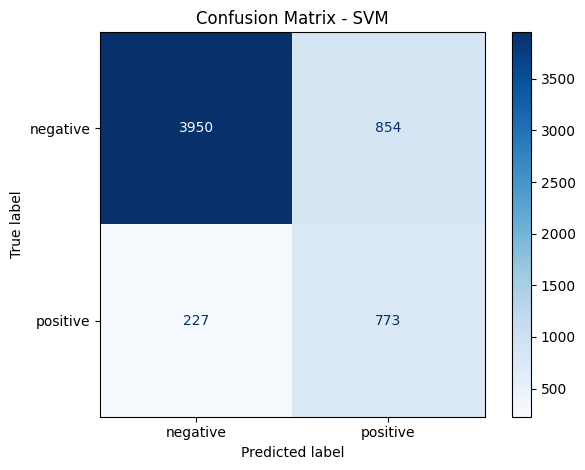

In [16]:
# Predict on test set
y_pred = model.predict(X_test_tfidf)

# Confusion matrix using encoded integer labels
cm = confusion_matrix(y_test_encoded, y_pred)

# Display with original class names
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - SVM")
plt.grid(False)
plt.tight_layout()
plt.show()

# Multinomial Naive-Bayes


🔁 Fold 1/5
✅ Accuracy: 0.7884
              precision    recall  f1-score   support

    negative       0.76      0.85      0.80      1600
    positive       0.83      0.72      0.77      1600

    accuracy                           0.79      3200
   macro avg       0.79      0.79      0.79      3200
weighted avg       0.79      0.79      0.79      3200


🔁 Fold 2/5
✅ Accuracy: 0.7477
              precision    recall  f1-score   support

    negative       0.75      0.75      0.75      1600
    positive       0.75      0.74      0.75      1599

    accuracy                           0.75      3199
   macro avg       0.75      0.75      0.75      3199
weighted avg       0.75      0.75      0.75      3199


🔁 Fold 3/5
✅ Accuracy: 0.7580
              precision    recall  f1-score   support

    negative       0.75      0.77      0.76      1600
    positive       0.76      0.75      0.76      1599

    accuracy                           0.76      3199
   macro avg       0.76      0.76  

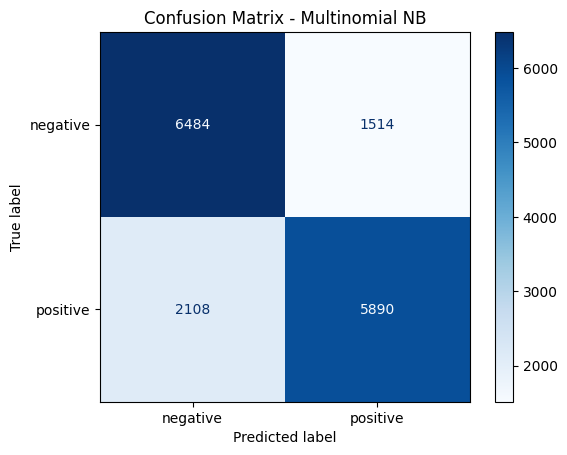

In [17]:
# Parameters
k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

all_true = []
all_pred = []
all_prob = []

accuracies = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_all, y_train_bal)):
    print(f"\n🔁 Fold {fold + 1}/{k}")
    
    X_tr, X_val = X_all[train_idx], X_all[val_idx]
    y_tr, y_val = np.array(y_train_bal)[train_idx], np.array(y_train_bal)[val_idx]

    model = MultinomialNB()
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)

    acc = accuracy_score(y_val, y_pred)
    accuracies.append(acc)
    print(f"✅ Accuracy: {acc:.4f}")
    print(classification_report(y_val, y_pred, target_names=label_encoder.classes_))

    all_true.extend(y_val)
    all_pred.extend(y_pred)
    all_prob.extend(y_proba)

# 🔷 Confusion Matrix
print("\n🧾 Confusion Matrix:")
cm = confusion_matrix(all_true, all_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Multinomial NB")
plt.show()


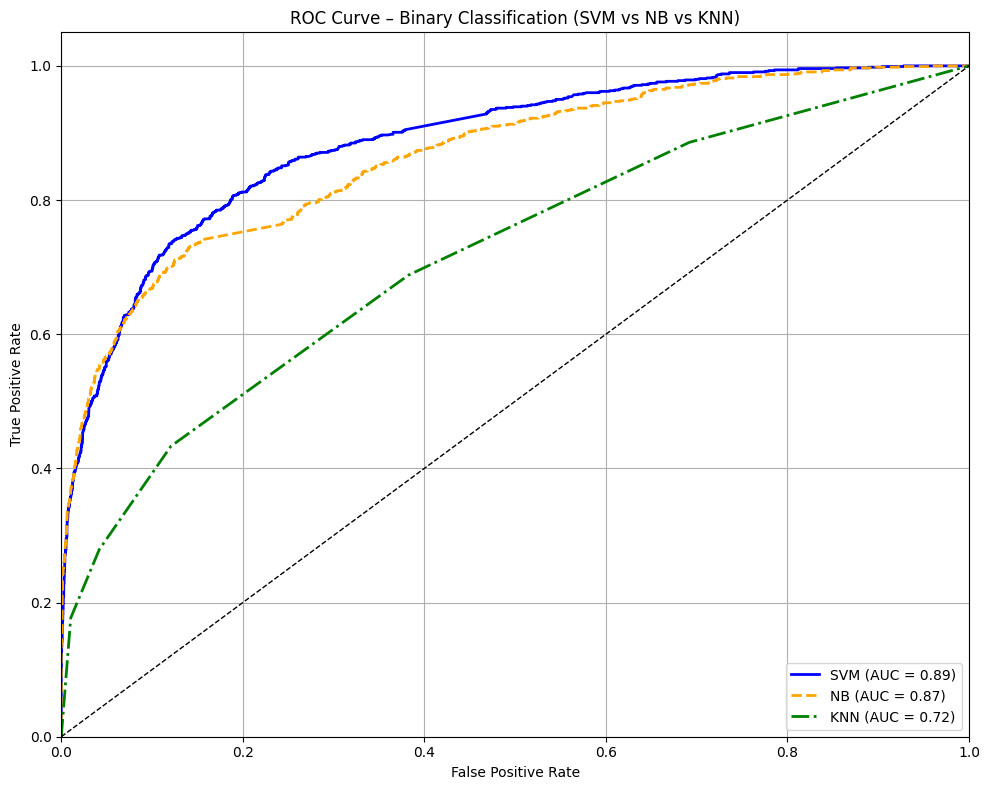

In [18]:
from sklearn.neighbors import KNeighborsClassifier

# 1. Make sure labels are binarized
n_classes = 2
y_test_bin = label_binarize(y_test_encoded, classes=[0, 1])

# 2. Calibrated Linear SVM
base_svc = LinearSVC(class_weight='balanced', max_iter=10000, dual='auto')
calibrated_svc = CalibratedClassifierCV(base_svc, method='sigmoid', cv=3)
calibrated_svc.fit(X_all, y_train_encoded)
y_score_svc = calibrated_svc.predict_proba(X_test_tfidf)[:, 1]

# 3. Multinomial NB
nb_model = MultinomialNB()
nb_model.fit(X_all, y_train_encoded)
y_score_nb = nb_model.predict_proba(X_test_tfidf)[:, 1]

# 4. K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_all, y_train_encoded)
y_score_knn = knn_model.predict_proba(X_test_tfidf)[:, 1]

# 5. Compute ROC curves
fpr_svc, tpr_svc, _ = roc_curve(y_test_encoded, y_score_svc)
roc_auc_svc = auc(fpr_svc, tpr_svc)

fpr_nb, tpr_nb, _ = roc_curve(y_test_encoded, y_score_nb)
roc_auc_nb = auc(fpr_nb, tpr_nb)

fpr_knn, tpr_knn, _ = roc_curve(y_test_encoded, y_score_knn)
roc_auc_knn = auc(fpr_knn, tpr_knn)

# 6. Plot ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_svc, tpr_svc, color='blue', lw=2, label=f'SVM (AUC = {roc_auc_svc:.2f})')
plt.plot(fpr_nb, tpr_nb, color='orange', lw=2, linestyle='--', label=f'NB (AUC = {roc_auc_nb:.2f})')
plt.plot(fpr_knn, tpr_knn, color='green', lw=2, linestyle='-.', label=f'KNN (AUC = {roc_auc_knn:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Binary Classification (SVM vs NB vs KNN)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


## Bengali Dataset Classes and Loaders

In [10]:
# Dataset Class
class BengaliDataset(Dataset):
    def __init__(self, padded_sequences, labels):
        self.sequences = torch.tensor(padded_sequences, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

train_loader = DataLoader(BengaliDataset(X_train_pad, y_train_encoded), batch_size=64, shuffle=True)
val_loader = DataLoader(BengaliDataset(X_val_pad, y_val_encoded), batch_size=64)
test_loader = DataLoader(BengaliDataset(X_test_pad, y_test_encoded), batch_size=64)

In [11]:
# # 3. Load FastText Embeddings
# from gensim.models import KeyedVectors
# fasttext_model = KeyedVectors.load_word2vec_format("cc.bn.300.vec")

# fasttext_model.save("cc.bn.300_PN.kv")
# print("✅ FastText model saved in .kv format")

In [12]:
# Much faster than reloading .vec every time
from gensim.models import KeyedVectors
fasttext_model = KeyedVectors.load("cc.bn.300.kv")

embedding_dim = 300
vocab_size = len(keras_tokenizer.word_index) + 1
embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, idx in keras_tokenizer.word_index.items():
    if word in fasttext_model:
        embedding_matrix[idx] = fasttext_model[word]
    else:
        embedding_matrix[idx] = np.random.normal(scale=0.6, size=(embedding_dim,))

print(embedding_matrix.shape)

(55097, 300)


# General Setup of CV(K-fold)

In [13]:
import gc
def run_kfold_cv(
    model_class, X, y, embedding_matrix=None, k=2, batch_size=32,
    epochs=30, model_save_dir="Bi-LSTM Models", test_loader=None,
    early_stopping_patience=3, model_name="Bi-LSTM"
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    os.makedirs(model_save_dir, exist_ok=True)

    all_fold_acc = []
    best_fold_idx = -1
    best_fold_val_acc = 0.0
    best_fold_train_losses, best_fold_val_losses = [], []
    best_fold_train_accs, best_fold_val_accs = [], []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\n🔁 Fold {fold + 1}/{k}")

        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        train_loader = DataLoader(BengaliDataset(X_train, y_train), batch_size=batch_size, shuffle=True, pin_memory=True)
        val_loader = DataLoader(BengaliDataset(X_val, y_val), batch_size=batch_size, pin_memory=True)

        model = model_class(embedding_matrix=embedding_matrix).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
        criterion = nn.CrossEntropyLoss()

        train_losses, val_losses = [], []
        train_accuracies, val_accuracies = [], []

        best_val_loss = float('inf')
        patience_counter = 0

        for epoch in range(epochs):
            model.train()
            total_loss, correct, total = 0, 0, 0

            for inputs, labels in train_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                total_loss += loss.item()
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

            avg_train_loss = total_loss / len(train_loader)
            train_acc = correct / total
            train_losses.append(avg_train_loss)
            train_accuracies.append(train_acc)

            # Validation
            model.eval()
            val_loss, correct, total = 0, 0, 0
            with torch.no_grad():
                for inputs, labels in val_loader:
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = model(inputs)
                    val_loss += criterion(outputs, labels).item()
                    preds = outputs.argmax(dim=1)
                    correct += (preds == labels).sum().item()
                    total += labels.size(0)

            avg_val_loss = val_loss / len(val_loader)
            val_acc = correct / total
            val_losses.append(avg_val_loss)
            val_accuracies.append(val_acc)

            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                patience_counter = 0
                best_model_path = os.path.join(model_save_dir, f"best_fold_{fold+1}.pth")
                torch.save(model.state_dict(), best_model_path)
                print(f"✅ Saved best model for fold {fold+1} at epoch {epoch+1}")
            else:
                patience_counter += 1
                if patience_counter >= early_stopping_patience:
                    print(f"⏹️ Early stopping at epoch {epoch+1} for fold {fold+1}")
                    break

        all_fold_acc.append(val_accuracies[-1])

        if val_accuracies[-1] > best_fold_val_acc:
            best_fold_val_acc = val_accuracies[-1]
            best_fold_idx = fold + 1
            best_fold_train_losses = train_losses
            best_fold_val_losses = val_losses
            best_fold_train_accs = train_accuracies
            best_fold_val_accs = val_accuracies

        # Load best model from this fold
        model.load_state_dict(torch.load(os.path.join(model_save_dir, f"best_fold_{fold+1}.pth")))
        model.eval()

        # Final evaluation for this fold
        with torch.no_grad():
            all_preds = model(torch.tensor(X_val).to(device)).argmax(dim=1).cpu().numpy()
        print(classification_report(y_val, all_preds, target_names=label_encoder.classes_))

        # Clear GPU memory after each fold
        del model, optimizer, train_loader, val_loader
        torch.cuda.empty_cache()
        gc.collect()

    print(f"\n🏆 Best Fold: {best_fold_idx} | Best Accuracy: {best_fold_val_acc:.4f}")

    # 📉 Plot Loss
    plt.figure(figsize=(10, 6))
    plt.plot(best_fold_train_losses, label="Train Loss", linestyle='-')
    plt.plot(best_fold_val_losses, label="Validation Loss", linestyle='--')
    plt.title(f"{model_name} Model: Training and Validation Loss (Best Fold {best_fold_idx})")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    plt.close()

    # 📈 Plot Accuracy
    plt.figure(figsize=(10, 6))
    plt.plot(best_fold_train_accs, label="Train Accuracy", linestyle='-')
    plt.plot(best_fold_val_accs, label="Validation Accuracy", linestyle='--')
    plt.title(f"{model_name} Model: Training and Validation Accuracy (Best Fold {best_fold_idx})")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    plt.close()


In [14]:
def evaluate_all_folds_on_test(
    model_class,
    label_encoder,
    model_dir,
    input_type="standard",     # or "bert"
    embedding_matrix=None,
    device=None,
    max_folds=20,
    batch_size=32,
    X_test=None,
    y_test=None,
    tokenizer=None,
    test_loader=None,
    max_len=100
):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Build test_loader if not provided
    if test_loader is None:
        assert X_test is not None and y_test is not None, "X_test and y_test must be provided if test_loader is not."
        
        if input_type == "bert":
            assert tokenizer is not None, "Tokenizer must be provided for BERT input."
            test_dataset = BERTDataset(X_test, y_test, tokenizer, max_len=max_len)
        else:
            test_dataset = BengaliDataset(X_test, y_test)

        test_loader = DataLoader(test_dataset, batch_size=batch_size)

    best_model = None
    best_acc = 0.0
    best_model_path = None

    # ✅ Always pass embedding_matrix (even if None)
    for fold_num in range(1, max_folds + 1):
        model_path = os.path.join(model_dir, f"best_fold_{fold_num}.pth")
        if not os.path.exists(model_path):
            continue

        print(f"\n📦 Loading best model from fold {fold_num}: {model_path}")
        model = model_class(embedding_matrix=embedding_matrix).to(device)

        model.load_state_dict(torch.load(model_path))
        model.eval()

        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in test_loader:
                if input_type == "bert":
                    input_ids = batch['input_ids'].to(device)
                    attention_mask = batch['attention_mask'].to(device)
                    labels = batch['labels'].to(device)
                    outputs = model(input_ids, attention_mask)
                else:
                    inputs, labels = batch
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = model(inputs)

                preds = torch.argmax(outputs, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        acc = accuracy_score(all_labels, all_preds)
        print(f"🧪 Fold {fold_num} Test Accuracy: {acc:.4f}")
        print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

        if acc > best_acc:
            best_acc = acc
            best_model = model
            best_model_path = model_path

    if best_model:
        print(f"\n🏆 Best model loaded from: {best_model_path}")
        print(f"✅ Highest Test Accuracy: {best_acc:.4f}")
        return best_model, best_model_path, best_acc
    else:
        print("⚠️ No valid fold models found.")
        return None, None, None


# Bi-LSTM model

In [15]:
# 5. BiLSTM Model with Pretrained Embedding
class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim=128, output_dim=2, freeze=False):
        super(BiLSTMClassifier, self).__init__()
        num_embeddings, embedding_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=freeze,
            padding_idx=0
        )
        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True, num_layers=1, dropout=0)
        self.dropout = nn.Dropout(0.6) # increased dropout for overfitting
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.bilstm(x)
        hidden_cat = torch.cat((hidden[-2], hidden[-1]), dim=1)
        x = self.dropout(hidden_cat)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [17]:
run_kfold_cv(
    model_class=lambda embedding_matrix: BiLSTMClassifier(
        embedding_matrix=embedding_matrix,
        hidden_dim=128,
        output_dim=3,   # or 3 for multi-class
        freeze=True
    ),
    X=X_np,
    y=y_np,
    embedding_matrix=embedding_matrix,
    k=5,
    batch_size=32, # smaller batch size helps generalization
    epochs=50, # early stopping will prevent overtraining
    model_save_dir="Bi_LSTM_Models",
    test_loader=test_loader,
    early_stopping_patience=3, # <- needs to be supported in your loop
    model_name="Bi-LSTM"
)


🔁 Fold 1/5


RuntimeError: CUDA error: device-side assert triggered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [ ]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix: BiLSTMClassifier(
        embedding_matrix=embedding_matrix,
        hidden_dim=128,
        output_dim=3,
        freeze=False
    ),
    label_encoder=label_encoder,
    model_dir="Bi_LSTM_Models",
    embedding_matrix=embedding_matrix,
    input_type="standard",
    X_test=X_test_pad,
    y_test=y_test_encoded
)

In [ ]:
# Load best model from the folder
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.load_state_dict(torch.load(best_model_path))
best_model.to(device)
best_model.eval()

# CNN Text Classification with PyTorch – Full Pipeline

In [25]:
#2. CNN Model for Text Classification
class CNNTextClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, output_dim=2, kernel_sizes=[3,4,5], num_filters=100, dropout=0.6, embedding_weights=None, freeze=True):
        super(CNNTextClassifier, self).__init__()
        
        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=freeze,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embedding_dim)) for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), output_dim)

    def forward(self, x):
        embedded = self.embedding(x)              # (batch_size, seq_len, embed_dim)
        embedded = embedded.unsqueeze(1)          # (batch_size, 1, seq_len, embed_dim)

        conved = [F.relu(conv(embedded)).squeeze(3) for conv in self.convs]  # [(batch_size, num_filters, ~), ...]

        pooled = [F.max_pool1d(c, c.shape[2]).squeeze(2) for c in conved]   # [(batch_size, num_filters), ...]

        cat = torch.cat(pooled, dim=1)            # (batch_size, num_filters * len(kernel_sizes))
        return self.fc(self.dropout(cat))



🔁 Fold 1/5
Epoch 1/50 | Train Loss: 0.5763 | Val Loss: 0.4963 | Train Acc: 0.7302 | Val Acc: 0.7844
✅ Saved best model for fold 1 at epoch 1
Epoch 2/50 | Train Loss: 0.4413 | Val Loss: 0.4846 | Train Acc: 0.8124 | Val Acc: 0.7934
✅ Saved best model for fold 1 at epoch 2
Epoch 3/50 | Train Loss: 0.3728 | Val Loss: 0.4992 | Train Acc: 0.8456 | Val Acc: 0.7991
Epoch 4/50 | Train Loss: 0.3319 | Val Loss: 0.5072 | Train Acc: 0.8691 | Val Acc: 0.8069
Epoch 5/50 | Train Loss: 0.3013 | Val Loss: 0.5234 | Train Acc: 0.8824 | Val Acc: 0.8125
⏹️ Early stopping at epoch 5 for fold 1
              precision    recall  f1-score   support

    negative       0.81      0.77      0.79      1600
    positive       0.78      0.82      0.80      1600

    accuracy                           0.79      3200
   macro avg       0.79      0.79      0.79      3200
weighted avg       0.79      0.79      0.79      3200


🔁 Fold 2/5
Epoch 1/50 | Train Loss: 0.5761 | Val Loss: 0.5032 | Train Acc: 0.7306 | Val Acc: 

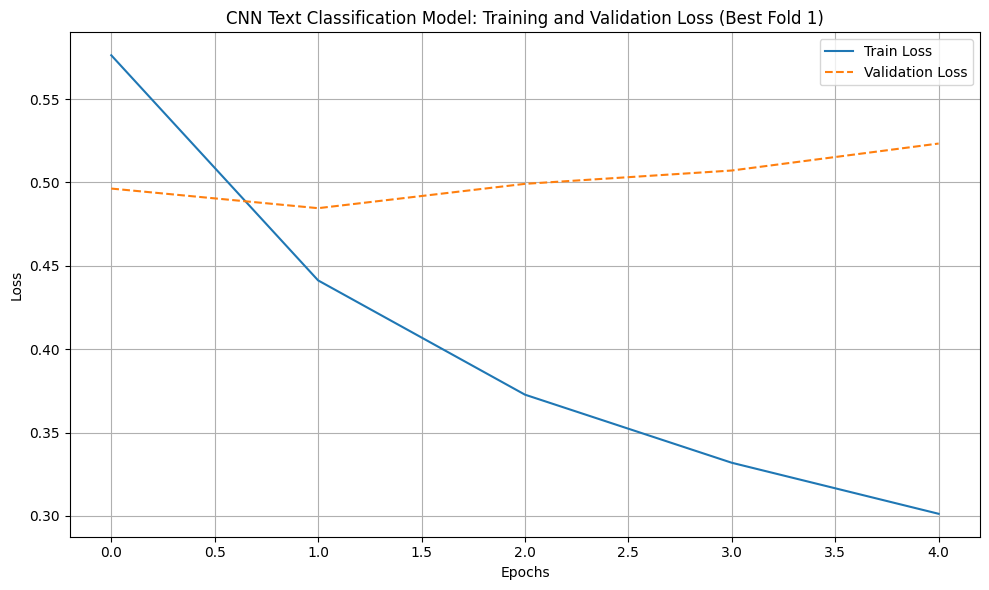

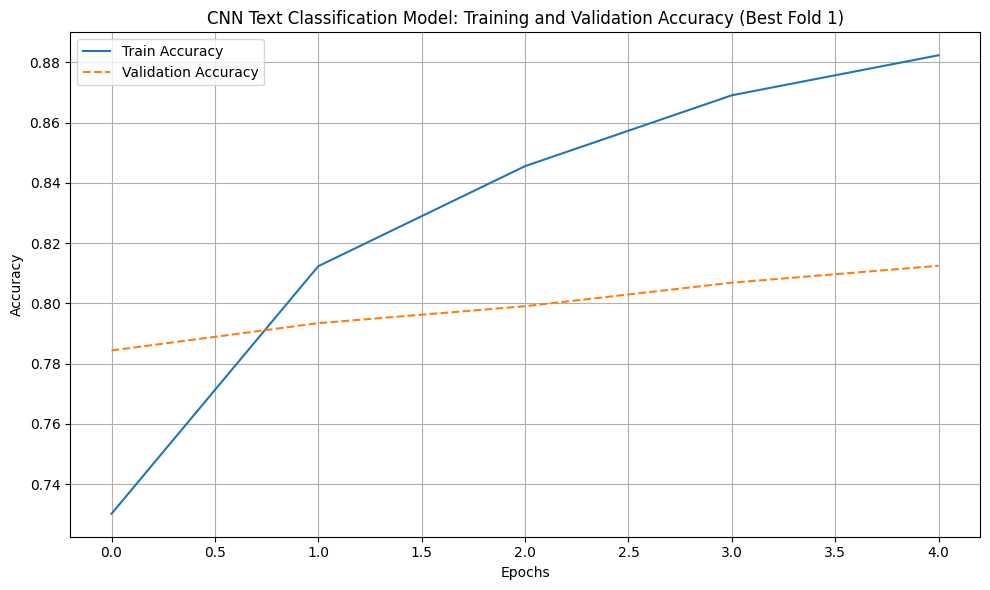

In [26]:
run_kfold_cv(
    model_class=lambda embedding_matrix: CNNTextClassifier(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        output_dim=2,
        dropout=0.6,
        embedding_weights=embedding_matrix,  # Set if you want FastText
        freeze=True
    ),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=embedding_matrix,       # Optional; used only if not None
    k=5,
    batch_size=32,
    epochs=50,
    model_save_dir="CNN_Models",
    test_loader=test_loader,
    early_stopping_patience=3,                # Add this to use early stopping
    model_name="CNN Text Classification"
)

In [27]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix: CNNTextClassifier(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        output_dim=2,
        dropout=0.6,
        embedding_weights=embedding_matrix,  # Set if you want FastText
        freeze=True
    ),                      # same lambda
    label_encoder=label_encoder,
    model_dir="CNN_Models",
    input_type="standard",
    embedding_matrix=None,
    X_test=X_test_pad,
    y_test=y_test_encoded
)



📦 Loading best model from fold 1: CNN_Models\best_fold_1.pth
🧪 Fold 1 Test Accuracy: 0.7181
              precision    recall  f1-score   support

    negative       0.98      0.68      0.80      4804
    positive       0.37      0.92      0.53      1000

    accuracy                           0.72      5804
   macro avg       0.67      0.80      0.66      5804
weighted avg       0.87      0.72      0.75      5804


📦 Loading best model from fold 2: CNN_Models\best_fold_2.pth
🧪 Fold 2 Test Accuracy: 0.5426
              precision    recall  f1-score   support

    negative       0.98      0.46      0.62      4804
    positive       0.27      0.96      0.42      1000

    accuracy                           0.54      5804
   macro avg       0.62      0.71      0.52      5804
weighted avg       0.86      0.54      0.59      5804


📦 Loading best model from fold 3: CNN_Models\best_fold_3.pth
🧪 Fold 3 Test Accuracy: 0.6590
              precision    recall  f1-score   support

    negative

In [28]:
# Load best CNN model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.load_state_dict(torch.load(best_model_path))
best_model.to(device)
best_model.eval()


CNNTextClassifier(
  (embedding): Embedding(26965, 300, padding_idx=0)
  (convs): ModuleList(
    (0): Conv2d(1, 100, kernel_size=(3, 300), stride=(1, 1))
    (1): Conv2d(1, 100, kernel_size=(4, 300), stride=(1, 1))
    (2): Conv2d(1, 100, kernel_size=(5, 300), stride=(1, 1))
  )
  (dropout): Dropout(p=0.6, inplace=False)
  (fc): Linear(in_features=300, out_features=2, bias=True)
)

# Pipeline for CNN + Bi-LSTM Hybrid (PyTorch)

In [29]:
#1. Model Definition
class CNN_BiLSTM_Hybrid(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, output_dim=2, dropout=0.6, embedding_weights=None, freeze=True):
        super(CNN_BiLSTM_Hybrid, self).__init__()

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=freeze,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.conv1 = nn.Conv1d(in_channels=embedding_dim, out_channels=128, kernel_size=5)
        self.pool = nn.MaxPool1d(kernel_size=2)

        self.bilstm = nn.LSTM(input_size=128, hidden_size=hidden_dim, batch_first=True, bidirectional=True)

        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        x = self.embedding(x)                      # (batch_size, seq_len, embedding_dim)
        x = x.permute(0, 2, 1)                     # (batch_size, embedding_dim, seq_len)
        x = F.relu(self.conv1(x))                  # (batch_size, out_channels, new_seq_len)
        x = self.pool(x)                           # (batch_size, out_channels, pooled_len)
        x = x.permute(0, 2, 1)                     # (batch_size, pooled_len, out_channels)
        _, (hidden, _) = self.bilstm(x)            # hidden: (2, batch, hidden_dim)
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)  # (batch_size, hidden_dim * 2)
        x = self.dropout(hidden)
        x = F.relu(self.fc1(x))
        return self.fc2(x)



🔁 Fold 1/5
Epoch 1/50 | Train Loss: 0.4839 | Val Loss: 0.3676 | Train Acc: 0.7658 | Val Acc: 0.8366
✅ Saved best model for fold 1 at epoch 1
Epoch 2/50 | Train Loss: 0.3240 | Val Loss: 0.3438 | Train Acc: 0.8589 | Val Acc: 0.8497
✅ Saved best model for fold 1 at epoch 2
Epoch 3/50 | Train Loss: 0.2385 | Val Loss: 0.3455 | Train Acc: 0.9046 | Val Acc: 0.8578
Epoch 4/50 | Train Loss: 0.1669 | Val Loss: 0.4611 | Train Acc: 0.9364 | Val Acc: 0.8406
Epoch 5/50 | Train Loss: 0.1187 | Val Loss: 0.5387 | Train Acc: 0.9582 | Val Acc: 0.8387
⏹️ Early stopping at epoch 5 for fold 1
              precision    recall  f1-score   support

    negative       0.85      0.85      0.85      1600
    positive       0.85      0.85      0.85      1600

    accuracy                           0.85      3200
   macro avg       0.85      0.85      0.85      3200
weighted avg       0.85      0.85      0.85      3200


🔁 Fold 2/5
Epoch 1/50 | Train Loss: 0.4739 | Val Loss: 0.3935 | Train Acc: 0.7689 | Val Acc: 

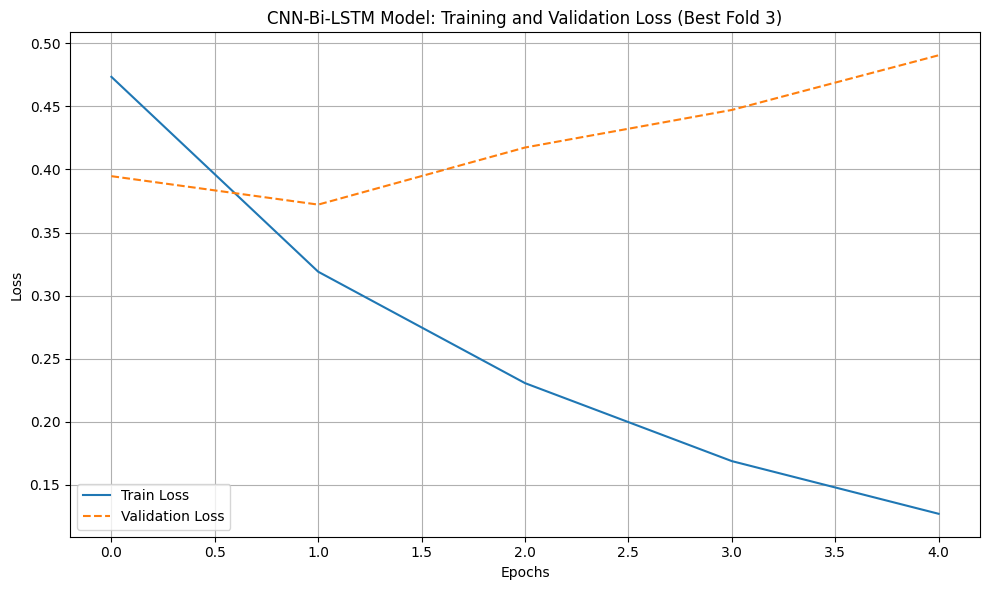

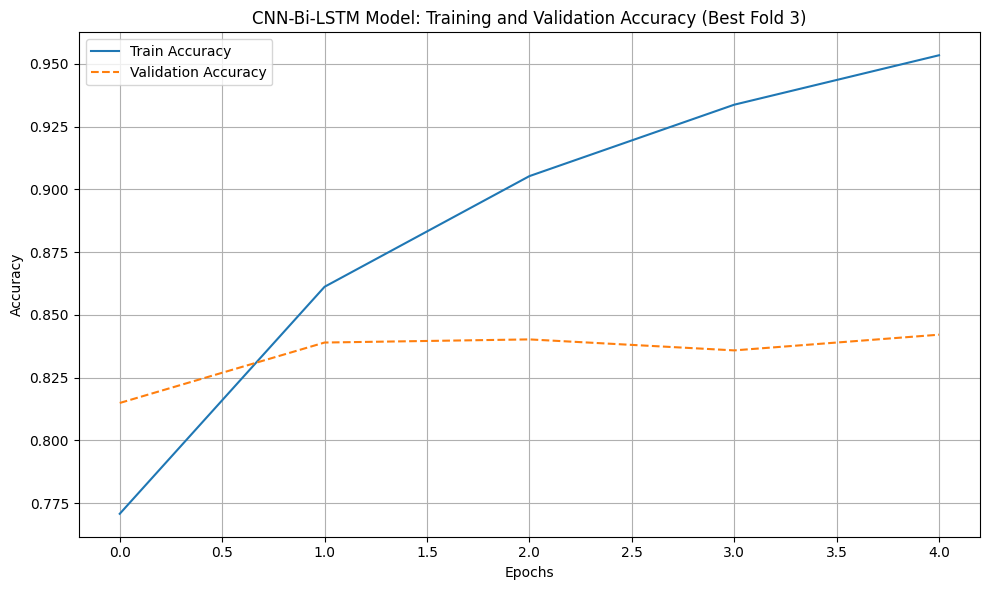

In [30]:
run_kfold_cv(
    model_class=lambda embedding_matrix: CNN_BiLSTM_Hybrid(
        vocab_size=embedding_matrix.shape[0],
        embedding_dim=embedding_matrix.shape[1],
        hidden_dim=128,                  # reduced from 256
        output_dim=2,
        dropout=0.6,                     # stronger regularization
        embedding_weights=embedding_matrix,
        freeze=True                      # freeze FastText initially
    ),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=embedding_matrix,
    k=5,
    batch_size=32,                      # smaller batch size = less overfit
    epochs=50,                          # pair with early stopping
    model_save_dir="CNN_BiLSTM_Models",
    test_loader=test_loader,
    early_stopping_patience=3,          # make sure run_kfold_cv uses this
    model_name="CNN-Bi-LSTM"
)


In [31]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix: CNN_BiLSTM_Hybrid(
        vocab_size=embedding_matrix.shape[0],
        embedding_dim=embedding_matrix.shape[1],
        hidden_dim=128,                  # reduced from 256
        output_dim=2,
        dropout=0.6,                     # stronger regularization
        embedding_weights=embedding_matrix,
        freeze=True                      # freeze FastText initially
    ),
    label_encoder=label_encoder,
    model_dir="CNN_BiLSTM_Models",
    input_type="standard",
    embedding_matrix=embedding_matrix,
    X_test=X_test_pad,
    y_test=y_test_encoded
)



📦 Loading best model from fold 1: CNN_BiLSTM_Models\best_fold_1.pth
🧪 Fold 1 Test Accuracy: 0.8265
              precision    recall  f1-score   support

    negative       0.97      0.82      0.89      4804
    positive       0.50      0.87      0.63      1000

    accuracy                           0.83      5804
   macro avg       0.73      0.84      0.76      5804
weighted avg       0.89      0.83      0.84      5804


📦 Loading best model from fold 2: CNN_BiLSTM_Models\best_fold_2.pth
🧪 Fold 2 Test Accuracy: 0.8353
              precision    recall  f1-score   support

    negative       0.96      0.84      0.89      4804
    positive       0.51      0.82      0.63      1000

    accuracy                           0.84      5804
   macro avg       0.74      0.83      0.76      5804
weighted avg       0.88      0.84      0.85      5804


📦 Loading best model from fold 3: CNN_BiLSTM_Models\best_fold_3.pth
🧪 Fold 3 Test Accuracy: 0.7979
              precision    recall  f1-score   

In [32]:
# Load best CNN BiLSTM model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.load_state_dict(torch.load(best_model_path))
best_model.to(device)
best_model.eval()


CNN_BiLSTM_Hybrid(
  (embedding): Embedding(26965, 300, padding_idx=0)
  (conv1): Conv1d(300, 128, kernel_size=(5,), stride=(1,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bilstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.6, inplace=False)
  (fc1): Linear(in_features=256, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

# Bi-LSTM + Attention Model in Keras

In [49]:
#1. Model Definition (Bi-LSTM + Attention)
class BiLSTM_Attention(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, output_dim=2, dropout=0.6, embedding_weights=None, freeze=True):
        super(BiLSTM_Attention, self).__init__()

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=freeze,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        embedded = self.embedding(x)                        # (batch_size, seq_len, embedding_dim)
        lstm_out, _ = self.bilstm(embedded)                 # (batch_size, seq_len, hidden_dim*2)

        attn_weights = torch.tanh(self.attention(lstm_out)) # (batch_size, seq_len, 1)
        attn_weights = torch.softmax(attn_weights, dim=1)   # softmax over time

        context = torch.sum(attn_weights * lstm_out, dim=1) # (batch_size, hidden_dim*2)

        x = self.dropout(context)
        x = F.relu(self.fc1(x))
        return self.fc2(x)



🔁 Fold 1/5
Epoch 1/30 | Train Loss: 0.5771 | Val Loss: 0.4415 | Train Acc: 0.6812 | Val Acc: 0.8087
✅ Saved best model for fold 1 at epoch 1
Epoch 2/30 | Train Loss: 0.4802 | Val Loss: 0.4086 | Train Acc: 0.7776 | Val Acc: 0.8166
✅ Saved best model for fold 1 at epoch 2
Epoch 3/30 | Train Loss: 0.3962 | Val Loss: 0.3654 | Train Acc: 0.8252 | Val Acc: 0.8400
✅ Saved best model for fold 1 at epoch 3
Epoch 4/30 | Train Loss: 0.3568 | Val Loss: 0.3576 | Train Acc: 0.8471 | Val Acc: 0.8434
✅ Saved best model for fold 1 at epoch 4
Epoch 5/30 | Train Loss: 0.3158 | Val Loss: 0.3437 | Train Acc: 0.8661 | Val Acc: 0.8556
✅ Saved best model for fold 1 at epoch 5
Epoch 6/30 | Train Loss: 0.2759 | Val Loss: 0.3428 | Train Acc: 0.8854 | Val Acc: 0.8584
✅ Saved best model for fold 1 at epoch 6
Epoch 7/30 | Train Loss: 0.2432 | Val Loss: 0.3600 | Train Acc: 0.9006 | Val Acc: 0.8656
Epoch 8/30 | Train Loss: 0.2182 | Val Loss: 0.3866 | Train Acc: 0.9093 | Val Acc: 0.8597
Epoch 9/30 | Train Loss: 0.203

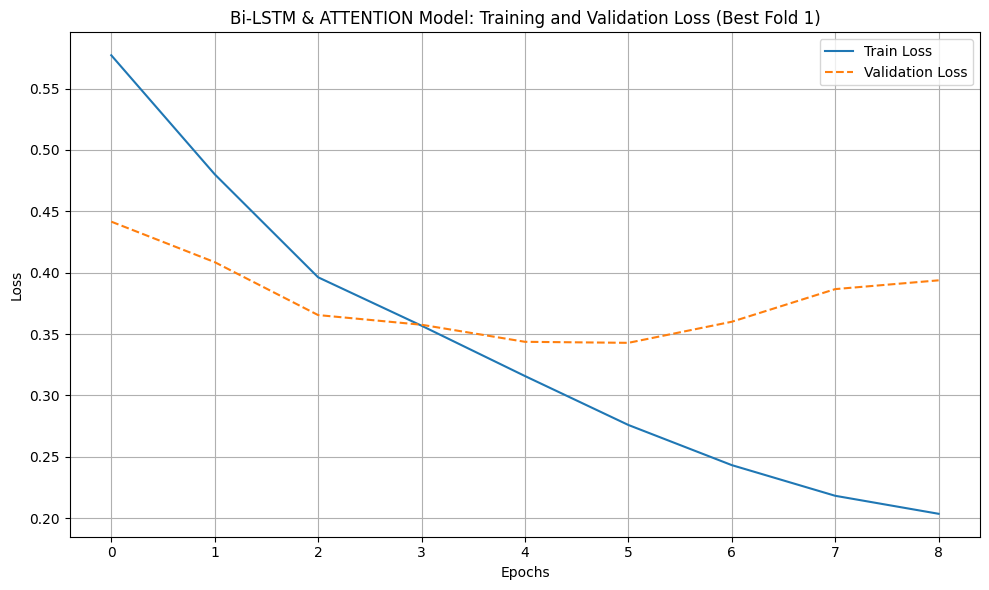

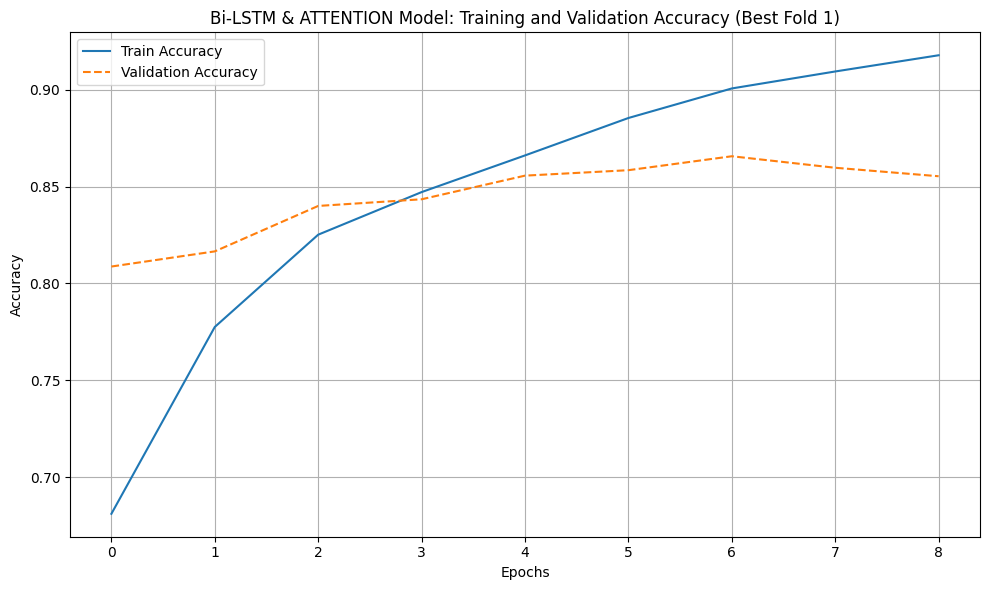

In [50]:
run_kfold_cv(
    model_class=lambda embedding_matrix: BiLSTM_Attention(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        hidden_dim=128,                  # reduced from 256
        output_dim=2,
        dropout=0.6,
        embedding_weights=embedding_matrix,
        freeze=True                      # Freeze pretrained FastText initially
    ),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=embedding_matrix,
    k=5,
    batch_size=32,                      # reduced for regularization
    epochs=30,                          # rely on early stopping
    model_save_dir="BiLSTM_Attention_Models",
    test_loader=test_loader,
    early_stopping_patience=3,          # ensure it’s supported in your loop
    model_name="Bi-LSTM & ATTENTION"
)


In [51]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix: BiLSTM_Attention(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        hidden_dim=128,                  # reduced from 256
        output_dim=2,
        dropout=0.6,
        embedding_weights=embedding_matrix,
        freeze=True                      # Freeze pretrained FastText initially
    ),
    label_encoder=label_encoder,
    model_dir="BiLSTM_Attention_Models",
    input_type="standard",
    embedding_matrix=embedding_matrix,
    X_test=X_test_pad,
    y_test=y_test_encoded
)


📦 Loading best model from fold 1: BiLSTM_Attention_Models\best_fold_1.pth
🧪 Fold 1 Test Accuracy: 0.8971
              precision    recall  f1-score   support

    negative       0.94      0.94      0.94      4804
    positive       0.70      0.70      0.70      1000

    accuracy                           0.90      5804
   macro avg       0.82      0.82      0.82      5804
weighted avg       0.90      0.90      0.90      5804


📦 Loading best model from fold 2: BiLSTM_Attention_Models\best_fold_2.pth
🧪 Fold 2 Test Accuracy: 0.8763
              precision    recall  f1-score   support

    negative       0.96      0.89      0.92      4804
    positive       0.61      0.80      0.69      1000

    accuracy                           0.88      5804
   macro avg       0.78      0.85      0.81      5804
weighted avg       0.90      0.88      0.88      5804


📦 Loading best model from fold 3: BiLSTM_Attention_Models\best_fold_3.pth
🧪 Fold 3 Test Accuracy: 0.8501
              precision    r

In [52]:
# Load best BiLSTM Attention model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.load_state_dict(torch.load(best_model_path))
best_model.to(device)
best_model.eval()


BiLSTM_Attention(
  (embedding): Embedding(26965, 300, padding_idx=0)
  (bilstm): LSTM(300, 128, batch_first=True, bidirectional=True)
  (attention): Linear(in_features=256, out_features=1, bias=True)
  (dropout): Dropout(p=0.6, inplace=False)
  (fc1): Linear(in_features=256, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

# An BERT + CNN + Bi-LSTM Hybrid Model (PyTorch)

In [53]:
def run_kfold_bert_cnn_lstm(X, y, k=2, num_classes=2, epochs=15, batch_size=16, max_len=100, patience=3, model_name="BERT-CNN-LSTM"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')
    os.makedirs("BERT_CNN_LSTM_Models", exist_ok=True)

    best_fold_idx = -1
    best_fold_val_acc = 0.0
    best_fold_train_losses, best_fold_val_losses = [], []
    best_fold_train_accs, best_fold_val_accs = [], []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\n🧪 Fold {fold+1}/{k}")

        X_train = [X[i] for i in train_idx]
        y_train = [y[i] for i in train_idx]
        X_val = [X[i] for i in val_idx]
        y_val = [y[i] for i in val_idx]

        train_dataset = BERTDataset(X_train, y_train, tokenizer, max_len)
        val_dataset = BERTDataset(X_val, y_val, tokenizer, max_len)

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size)

        model = BERT_CNN_LSTM(output_dim=num_classes).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=2e-5, weight_decay=1e-5)
        criterion = nn.CrossEntropyLoss()

        best_acc, patience_counter = 0.0, 0
        train_losses, val_losses = [], []
        train_accuracies, val_accuracies = [], []

        for epoch in range(epochs):
            model.train()
            total_loss, correct, total = 0, 0, 0

            # Optional: Unfreeze BERT after 3 epochs
            if epoch == 3:
                for param in model.bert.parameters():
                    param.requires_grad = True
                print("🔓 Unfroze BERT encoder for fine-tuning.")

            for batch in train_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                optimizer.zero_grad()
                outputs = model(input_ids, attention_mask)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                total_loss += loss.item()
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

            train_loss = total_loss / len(train_loader)
            train_acc = correct / total
            train_losses.append(train_loss)
            train_accuracies.append(train_acc)

            # Validation
            model.eval()
            val_loss, correct, total = 0, 0, 0
            with torch.no_grad():
                for batch in val_loader:
                    input_ids = batch['input_ids'].to(device)
                    attention_mask = batch['attention_mask'].to(device)
                    labels = batch['labels'].to(device)

                    outputs = model(input_ids, attention_mask)
                    loss = criterion(outputs, labels)
                    val_loss += loss.item()

                    preds = outputs.argmax(dim=1)
                    correct += (preds == labels).sum().item()
                    total += labels.size(0)

            val_loss /= len(val_loader)
            val_acc = correct / total
            val_losses.append(val_loss)
            val_accuracies.append(val_acc)

            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

            # Early stopping check
            if val_acc > best_acc:
                best_acc = val_acc
                patience_counter = 0
                torch.save(model.state_dict(), f"BERT_CNN_LSTM_Models/best_fold_{fold+1}.pth")
                print(f"✅ Saved best model for fold {fold+1}")
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print("⏹️ Early stopping triggered.")
                    break

        # Track best fold
        if best_acc > best_fold_val_acc:
            best_fold_val_acc = best_acc
            best_fold_idx = fold + 1
            best_fold_train_losses = train_losses
            best_fold_val_losses = val_losses
            best_fold_train_accs = train_accuracies
            best_fold_val_accs = val_accuracies

    print(f"\n🏆 Best Fold: {best_fold_idx} | Best Accuracy: {best_fold_val_acc:.4f}")

    # 📉 Plot Loss
    plt.figure(figsize=(10, 6))
    plt.plot(best_fold_train_losses, label="Train Loss", linestyle='-')
    plt.plot(best_fold_val_losses, label="Validation Loss", linestyle='--')
    plt.title(f"{model_name} Model: Training and Validation Loss (Best Fold {best_fold_idx})")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 📈 Plot Accuracy
    plt.figure(figsize=(10, 6))
    plt.plot(best_fold_train_accs, label="Train Accuracy", linestyle='-')
    plt.plot(best_fold_val_accs, label="Validation Accuracy", linestyle='--')
    plt.title(f"{model_name} Model: Training and Validation Accuracy (Best Fold {best_fold_idx})")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [54]:
class BERT_CNN_LSTM(nn.Module):
    def __init__(self, bert_model_name='bert-base-multilingual-cased', hidden_dim=96, output_dim=2, dropout=0.6):
        super(BERT_CNN_LSTM, self).__init__()

        self.bert = AutoModel.from_pretrained(bert_model_name)
        for param in self.bert.parameters():
            param.requires_grad = False  # freeze initially

        self.conv1 = nn.Conv1d(in_channels=self.bert.config.hidden_size, out_channels=128, kernel_size=3, padding=1)
        self.lstm = nn.LSTM(input_size=128, hidden_size=hidden_dim, batch_first=True, bidirectional=True)

        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, input_ids, attention_mask):
        bert_outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        x = bert_outputs.last_hidden_state

        x = x.permute(0, 2, 1)
        x = F.relu(self.conv1(x))
        x = x.permute(0, 2, 1)

        lstm_out, _ = self.lstm(x)
        pooled = torch.mean(lstm_out, dim=1)

        x = self.dropout(pooled)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


In [55]:
class BERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=100):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer.encode_plus(
            str(self.texts[idx]),
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }


In [ ]:
run_kfold_bert_cnn_lstm(X_train_bal_clean, y_train_encoded, k=3, num_classes=2, epochs=15, batch_size=16, patience=3, model_name="BERT-CNN-LSTM")


🧪 Fold 1/3
Epoch 1/15 | Train Loss: 0.6283 | Val Loss: 0.4943 | Train Acc: 0.6431 | Val Acc: 0.7710
✅ Saved best model for fold 1
Epoch 2/15 | Train Loss: 0.4973 | Val Loss: 0.4563 | Train Acc: 0.7652 | Val Acc: 0.7944
✅ Saved best model for fold 1


In [ ]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix=None: BERT_CNN_LSTM(output_dim=len(label_encoder.classes_)),
    label_encoder=label_encoder,
    model_dir="BERT_CNN_LSTM_Models",
    input_type="bert",
    X_test=X_test_clean,
    y_test=y_test_encoded,
    tokenizer=AutoTokenizer.from_pretrained("bert-base-multilingual-cased"),
    max_len=100
)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.load_state_dict(torch.load(best_model_path))
best_model.to(device)
best_model.eval()


# BERT + GRU + Attention

In [ ]:
def run_kfold_bert_gru_att(X, y, k=2, num_classes=2, epochs=15, batch_size=16, max_len=100, patience=3, model_name="BERT-GRU-ATTENTION"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')
    os.makedirs("BERT_CNN_LSTM_Models", exist_ok=True)

    best_fold_idx = -1
    best_fold_val_acc = 0.0
    best_fold_train_losses, best_fold_val_losses = [], []
    best_fold_train_accs, best_fold_val_accs = [], []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\n🧪 Fold {fold+1}/{k}")

        X_train = [X[i] for i in train_idx]
        y_train = [y[i] for i in train_idx]
        X_val = [X[i] for i in val_idx]
        y_val = [y[i] for i in val_idx]

        train_dataset = BERTDataset(X_train, y_train, tokenizer, max_len)
        val_dataset = BERTDataset(X_val, y_val, tokenizer, max_len)

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size)

        model = BERT_GRU_ATTENTION(output_dim=num_classes).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=2e-5, weight_decay=1e-5)
        criterion = nn.CrossEntropyLoss()

        best_acc, patience_counter = 0.0, 0
        train_losses, val_losses = [], []
        train_accuracies, val_accuracies = [], []

        for epoch in range(epochs):
            model.train()
            total_loss, correct, total = 0, 0, 0

            # Optional: Unfreeze BERT after 3 epochs
            if epoch == 3:
                for param in model.bert.parameters():
                    param.requires_grad = True
                print("🔓 Unfroze BERT encoder for fine-tuning.")

            for batch in train_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                optimizer.zero_grad()
                outputs = model(input_ids, attention_mask)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                total_loss += loss.item()
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

            train_loss = total_loss / len(train_loader)
            train_acc = correct / total
            train_losses.append(train_loss)
            train_accuracies.append(train_acc)

            # Validation
            model.eval()
            val_loss, correct, total = 0, 0, 0
            with torch.no_grad():
                for batch in val_loader:
                    input_ids = batch['input_ids'].to(device)
                    attention_mask = batch['attention_mask'].to(device)
                    labels = batch['labels'].to(device)

                    outputs = model(input_ids, attention_mask)
                    loss = criterion(outputs, labels)
                    val_loss += loss.item()

                    preds = outputs.argmax(dim=1)
                    correct += (preds == labels).sum().item()
                    total += labels.size(0)

            val_loss /= len(val_loader)
            val_acc = correct / total
            val_losses.append(val_loss)
            val_accuracies.append(val_acc)

            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

            # Early stopping check
            if val_acc > best_acc:
                best_acc = val_acc
                patience_counter = 0
                torch.save(model.state_dict(), f"BERT_CNN_LSTM_Models/best_fold_{fold+1}.pth")
                print(f"✅ Saved best model for fold {fold+1}")
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print("⏹️ Early stopping triggered.")
                    break

        # Track best fold
        if best_acc > best_fold_val_acc:
            best_fold_val_acc = best_acc
            best_fold_idx = fold + 1
            best_fold_train_losses = train_losses
            best_fold_val_losses = val_losses
            best_fold_train_accs = train_accuracies
            best_fold_val_accs = val_accuracies

    print(f"\n🏆 Best Fold: {best_fold_idx} | Best Accuracy: {best_fold_val_acc:.4f}")

    # 📉 Plot Loss
    plt.figure(figsize=(10, 6))
    plt.plot(best_fold_train_losses, label="Train Loss", linestyle='-')
    plt.plot(best_fold_val_losses, label="Validation Loss", linestyle='--')
    plt.title(f"{model_name} Model: Training and Validation Loss (Best Fold {best_fold_idx})")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 📈 Plot Accuracy
    plt.figure(figsize=(10, 6))
    plt.plot(best_fold_train_accs, label="Train Accuracy", linestyle='-')
    plt.plot(best_fold_val_accs, label="Validation Accuracy", linestyle='--')
    plt.title(f"{model_name} Model: Training and Validation Accuracy (Best Fold {best_fold_idx})")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [ ]:
class BERT_GRU_ATTENTION(nn.Module):
    def __init__(self, bert_model_name='bert-base-multilingual-cased', hidden_dim=128, output_dim=2, dropout=0.6):
        super(BERT_GRU_ATTENTION, self).__init__()

        self.bert = AutoModel.from_pretrained(bert_model_name)
        for param in self.bert.parameters():
            param.requires_grad = False  # freeze initially

        self.gru = nn.GRU(
            input_size=self.bert.config.hidden_size,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        x = outputs.last_hidden_state  # (batch_size, seq_len, hidden)

        gru_out, _ = self.gru(x)       # (batch_size, seq_len, hidden*2)

        # Attention
        attn_weights = torch.tanh(self.attention(gru_out))  # (batch, seq_len, 1)
        attn_weights = torch.softmax(attn_weights, dim=1)
        context = torch.sum(attn_weights * gru_out, dim=1)  # (batch, hidden*2)

        x = self.dropout(context)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


In [ ]:
class BERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=100):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer.encode_plus(
            str(self.texts[idx]),
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }


In [ ]:
run_kfold_bert_gru_att(X_train_bal_clean, y_train_encoded, k=3, num_classes=2, epochs=30, batch_size=16, model_name="BERT-GRU-ATTENTION")

In [ ]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix=None: BERT_GRU_ATTENTION(output_dim=len(label_encoder.classes_)),
    label_encoder=label_encoder,
    model_dir="BERT_GRU_ATTENTION_Models",
    input_type="bert",
    X_test=X_test_clean,
    y_test=y_test_encoded,
    tokenizer=AutoTokenizer.from_pretrained("bert-base-multilingual-cased"),
    max_len=100
)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.load_state_dict(torch.load(best_model_path))
best_model.to(device)
best_model.eval()
